# Robotic Waste Sorting with Deep Reinforcement Learning: Comparing PPO, TD3 and SAC
**Final experiments · UTS 43008 Reinforcement Learning, Assignment 3 · Group 53 (team 3H): Hyojeong Yu (PPO), Hyunbeen Suk (SAC), Heesu Kim (TD3)**

A Franka Panda arm in PyBullet (panda-gym) picks up real household waste items (3D scans from the YCB object set),
lifts them and lets them fall through the hole above the bin of their category: **plastic, paper or metal**. PPO, SAC
and TD3 (Stable-Baselines3) are compared on the same environment, budget, network size and evaluation.

This notebook contains the complete code of the final experiment (environment, algorithms, runners), the checks of
the environment and every result reported in the project report. The outputs shown are those of the actual runs.
The 1,000,000-step training runs (about 10 hours in total) were launched with the runner scripts written by the cells
below and are not re-run inside the notebook (Section 6 shows how and when they ran).

**Main result** (final runs, five training seeds, 50 unseen test episodes each):

| | PPO | SAC | TD3 |
|---|---|---|---|
| Selected configuration | PPO_small_lr | SAC_robotics_gamma | TD3_robotics_gamma |
| Test success, one item | 0% | **89.2% ± 19.8** (seeds: 100 / 100 / 98 / 54 / 94) | 0% |
| Gripper reached the item | 64% | 95% | 22% |
| Item lifted | 0% | 92% | 1.2% |
| Training time per run (1M steps) | 21 min | 85 min | 61 min |

With the same number of environment steps only SAC learned the task; it also cleared multi-item trays (84% of
items, whole tray 52% for three items). Two supplementary comparisons check the obvious objections: PPO with
observation and reward normalisation (reach 88%, still no lift) and an equal-training-time comparison
(PPO 4M steps, TD3 1.39M steps: still 0%).

**Contents**
0. Setup
1. Real waste items (YCB)
2. Environment
3. Environment checks
4. Algorithms and protocol
5. Runner scripts
6. How the experiment was run
7. Results: selection, main comparison, learning curves, where each algorithm stops, skills over training, robustness
   and trays, movement, supplementary comparisons, a rollout
8. Summary and limitations

## 0. Setup
Results were produced on an Apple M5 MacBook (CPU, one torch thread per run) with the versions in `requirements.txt`.
On Google Colab the cell installs the simulation and RL packages (Colab's own numpy and torch are kept); training is
not repeated there, so the outputs below stay those of the original runs.

In [1]:
import importlib.metadata as metadata, os, platform, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pybullet==3.2.7", "panda-gym==3.0.7",
                    "stable-baselines3==2.9.0", "gymnasium==1.3.0", "psutil"], check=True)
packages = ["pybullet", "panda-gym", "stable-baselines3", "gymnasium", "torch", "numpy", "pandas", "matplotlib"]
print(platform.platform(), "| Python", platform.python_version(), "| CPU cores:", os.cpu_count())
print({p: metadata.version(p) for p in packages})

macOS-26.6.2-arm64-arm-64bit | Python 3.11.16 | CPU cores: 10
{'pybullet': '3.2.7', 'panda-gym': '3.0.7', 'stable-baselines3': '2.9.0', 'gymnasium': '1.3.0', 'torch': '2.14.1', 'numpy': '1.26.4', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## 1. Real waste items (YCB)
Seven items from the YCB object and model set (Calli et al., 2015), chosen so that the Panda gripper (8 cm maximum
opening) can grasp them: plastic (mustard bottle, two cups), paper (sugar box, gelatin box stood on its edge), metal
(tomato soup can, potted meat can). The script downloads each 16k-face scan, builds its collision shape (PyBullet
V-HACD convex decomposition; one 80-vertex convex hull for the cups) and writes a URDF with the YCB mass. Existing
items are kept; the printed checksums identify the exact collision shapes used in every run.

In [2]:
%%writefile requirements.txt
pybullet==3.2.7
panda-gym==3.0.7
stable-baselines3==2.9.0
gymnasium==1.3.0
torch==2.14.1
numpy==1.26.4
pandas==3.0.6
matplotlib==3.11.2
psutil==7.2.2


Overwriting requirements.txt


In [3]:
%%writefile build_assets.py
"""Builds the seven YCB waste items used by waste_env.py into assets/ycb/ (same code as the Part C v6 notebook).

    python build_assets.py

For each object: downloads the 16k-face scan from the YCB object set (Calli et al., 2015; CC BY 4.0), builds the
collision shape (PyBullet V-HACD convex decomposition; one 80-vertex convex hull for the cups, which are only grasped
from the outside), and writes a URDF with the YCB mass and the centre of mass at the centre of the bounding box.
Existing objects are kept. Then prints SHA-1 checksums of the files the physics uses, to compare with the reference.
"""
import hashlib
import json
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
from scipy.spatial import ConvexHull

ASSET_DIR = Path(__file__).resolve().parent / "assets" / "ycb"
# name: (category, mass in kg from the YCB set, collision shape)
YCB_OBJECTS = {
    "006_mustard_bottle": ("plastic", 0.603, "vhacd"), "065-a_cups": ("plastic", 0.013, "hull"),
    "065-c_cups": ("plastic", 0.017, "hull"), "004_sugar_box": ("paper", 0.514, "vhacd"),
    "009_gelatin_box": ("paper", 0.097, "vhacd"), "005_tomato_soup_can": ("metal", 0.349, "vhacd"),
    "010_potted_meat_can": ("metal", 0.370, "vhacd"),
}
YCB_URL = "http://ycb-benchmarks.s3-website-us-east-1.amazonaws.com/data/google/{}_google_16k.tgz"
URDF_TEMPLATE = """<?xml version="1.0"?>
<robot name="{name}">
  <link name="baseLink">
    <contact><lateral_friction value="0.8"/><rolling_friction value="0.001"/><spinning_friction value="0.001"/></contact>
    <inertial>
      <origin rpy="0 0 0" xyz="{cx:.5f} {cy:.5f} {cz:.5f}"/>
      <mass value="{mass}"/>
      <inertia ixx="1e-4" ixy="0" ixz="0" iyy="1e-4" iyz="0" izz="1e-4"/>
    </inertial>
    <visual><geometry><mesh filename="textured.obj" scale="1 1 1"/></geometry></visual>
    <collision><geometry><mesh filename="collision.obj" scale="1 1 1"/></geometry></collision>
  </link>
</robot>
"""


def write_convex_hull(vertices, path, n_points=80):
    # One convex hull, reduced to n_points vertices by farthest-point sampling (keeps the outer shape).
    hull_points = vertices[ConvexHull(vertices).vertices]
    chosen = [int(np.argmax(np.linalg.norm(hull_points - hull_points.mean(0), axis=1)))]
    distance = np.linalg.norm(hull_points - hull_points[chosen[0]], axis=1)
    while len(chosen) < n_points:
        chosen.append(int(np.argmax(distance)))
        distance = np.minimum(distance, np.linalg.norm(hull_points - hull_points[chosen[-1]], axis=1))
    points = hull_points[chosen]
    hull = ConvexHull(points)
    index = {old: new for new, old in enumerate(hull.vertices)}
    with open(path, "w") as f:
        f.write("o convex_hull\n")
        for i in hull.vertices:
            f.write("v %.6f %.6f %.6f\n" % tuple(points[i]))
        for simplex in hull.simplices:
            a, b, c = points[simplex]
            if np.dot(np.cross(b - a, c - a), a - points.mean(0)) < 0:   # outward-facing triangles
                simplex = simplex[[0, 2, 1]]
            f.write("f %d %d %d\n" % tuple(index[i] + 1 for i in simplex))


def pybullet_client():
    import pybullet
    if not pybullet.isConnected():
        pybullet.connect(pybullet.DIRECT)
    return pybullet


def build_ycb_asset(name, mass, collision):
    folder = ASSET_DIR / name
    if (folder / "model.urdf").exists():
        return
    folder.mkdir(parents=True, exist_ok=True)
    archive = folder / "download.tgz"
    urllib.request.urlretrieve(YCB_URL.format(name), archive)
    with tarfile.open(archive) as tar:
        for member in ["textured.obj", "textured.mtl", "texture_map.png"]:
            source = tar.extractfile(f"{name}/google_16k/{member}")
            (folder / member).write_bytes(source.read())
    archive.unlink()
    vertices = np.array([[float(x) for x in line.split()[1:4]]
                         for line in open(folder / "textured.obj") if line.startswith("v ")])
    if collision == "hull":
        write_convex_hull(vertices, folder / "collision.obj")
    else:
        pybullet_client().vhacd(str(folder / "textured.obj"), str(folder / "collision.obj"), str(folder / "vhacd.log"),
                                resolution=200000)
    centre = (vertices.min(0) + vertices.max(0)) / 2
    (folder / "model.urdf").write_text(URDF_TEMPLATE.format(name=name, cx=centre[0], cy=centre[1], cz=centre[2], mass=mass))


def checksums():
    files = [ASSET_DIR / "catalogue.json"] + [ASSET_DIR / n / f for n in YCB_OBJECTS for f in ("collision.obj", "model.urdf")]
    return {str(f.relative_to(ASSET_DIR)): hashlib.sha1(f.read_bytes()).hexdigest()[:12] for f in files}


if __name__ == "__main__":
    catalogue = {}
    for name, (category, mass, collision) in YCB_OBJECTS.items():
        build_ycb_asset(name, mass, collision)
        vertices = np.array([[float(x) for x in line.split()[1:4]]
                             for line in open(ASSET_DIR / name / "textured.obj") if line.startswith("v ")])
        size = (vertices.max(0) - vertices.min(0)).round(4).tolist()
        catalogue[name] = {"category": category, "mass_kg": mass, "size_m": size}
        print(f"{name:<22} {category:<8} {mass:5.3f} kg   size x, y, z = {', '.join(f'{100 * s:.1f}' for s in size)} cm")
    with open(ASSET_DIR / "catalogue.json", "w") as f:
        json.dump(catalogue, f, indent=2)
    print(json.dumps(checksums(), indent=1))


Overwriting build_assets.py


In [4]:
!{sys.executable} build_assets.py

006_mustard_bottle     plastic  0.603 kg   size x, y, z = 9.7, 6.7, 19.1 cm
065-a_cups             plastic  0.013 kg   size x, y, z = 5.7, 5.7, 6.2 cm
065-c_cups             plastic  0.017 kg   size x, y, z = 6.5, 6.5, 6.7 cm
004_sugar_box          paper    0.514 kg   size x, y, z = 5.0, 9.4, 17.6 cm
009_gelatin_box        paper    0.097 kg   size x, y, z = 8.9, 10.1, 3.0 cm
005_tomato_soup_can    metal    0.349 kg   size x, y, z = 6.8, 6.8, 10.2 cm


010_potted_meat_can    metal    0.370 kg   size x, y, z = 10.2, 6.0, 8.3 cm
{
 "catalogue.json": "a98654417e2d",
 "006_mustard_bottle/collision.obj": "8cf555124dc2",
 "006_mustard_bottle/model.urdf": "c6d2dc7087d3",
 "065-a_cups/collision.obj": "017fe9164925",
 "065-a_cups/model.urdf": "c97d31f9b9d5",
 "065-c_cups/collision.obj": "125e501c2964",
 "065-c_cups/model.urdf": "a2c7d4315cdf",
 "004_sugar_box/collision.obj": "8024c42c7ebf",
 "004_sugar_box/model.urdf": "f7d01b827950",
 "009_gelatin_box/collision.obj": "7308e9e82b54",
 "009_gelatin_box/model.urdf": "fe3e0f7e762e",
 "005_tomato_soup_can/collision.obj": "7e052681cf21",
 "005_tomato_soup_can/model.urdf": "2bdfb50e3fc3",
 "010_potted_meat_can/collision.obj": "4cf1caf83ef6",
 "010_potted_meat_can/model.urdf": "37f9d6648cd7"
}


## 2. Environment
**Task.** One item lies on the tray (random item, position and yaw). The arm must grasp it, lift it at least 6 cm and
let it fall through the 14 cm hole above the bin of its category. An episode lasts at most 100 steps (0.04 s each).

| | |
|---|---|
| Action (5, in [-1, 1]) | gripper displacement x, y, z (up to 5 cm per step), wrist yaw (up to 0.25 rad per step), finger opening |
| Observation (33) | gripper position, velocity, finger width, wrist yaw (sin, cos); item position, orientation, linear and angular velocity, size, category (one-hot), lifted flag; vector from the gripper to the item's grasp point and the wrist angle relative to the item's narrow side (sin 2Δ, cos 2Δ) |
| Reward | potential-based shaping 10·(Φ(s') − Φ(s)) − 0.01 per step, +5 on success, −5 on failure. Before the lift Φ = −(gripper-to-item distance) − 0.5 + 5·lift height (capped at 6 cm) + 0.05 when both finger pads hold the item; after the lift Φ = −(gripper-to-item distance) − (item-to-hole distance) + 0.3 + 0.05 |
| Success | the lifted item falls through the hole of its category |
| Failure (episode ends) | wrong hole, item pushed into a hole without being lifted, item off the table |
| Regrasp | a lifted item put back on the table is not a failure: it has to be lifted again, and the reward of the lift is charged back |
| Reverse curriculum (training only) | some episodes start closer to the goal: held above the correct hole → held above the tray → gripper open around the item. Easy starts are 50% of episodes at first, falling to 0% at 60% of the training budget; a start type is passed when 10 of the last 20 attempts succeed (20% of easy starts replay passed types). One curriculum per run, shared by all of its training environments |
| Physical randomisation (training) | item mass and friction ×0.7–1.3, size ×0.9–1.1 per episode |
| Evaluation | normal start only, deterministic actions: nominal items, the training randomisation, and out-of-range items (mass ×2, friction ×0.5, size ×1.2, size ×0.8); trays of 3 and 4 items cleared outermost-first, spaced and dense (items 0–1 cm apart) |

The reward terms were checked for loops that earn reward without sorting (Section 3).

In [5]:
%%writefile waste_env.py
"""Final-stage environment for team 3H (Group 53): sorting real YCB waste items with a Panda arm (PyBullet).

This is the environment every algorithm uses in the final runs. Do not change this file; train_eval.py fixes every
setting of the final experiment. Same code as the environment used in development (tools/v9_env.py), with the final
settings as defaults (relative observation on, display meshes off) and the asset folder next to this file.

Task: pick the item on the tray, lift it, carry it and let it fall through the hole above the bin of its category
(plastic / paper / metal). Action = (dx, dy, dz, dyaw, gripper) in [-1, 1]. Episode = at most 100 steps.
- reward: potential-based shaping (reach, grasp, lift, carry), -0.01 per step, +5 success, -5 failure;
- regrasp: a lifted item put back on the table is not a failure; it has to be lifted again;
- reverse start-state curriculum (training only): above_bin -> in_hand -> pre_grasp;
- physical randomisation (training): mass and friction x0.7-1.3, size x0.9-1.1; evaluation also outside these ranges;
- evaluation helpers: run_episodes (one item), clear_tray (several items, optionally a dense tray).
"""
import json
from pathlib import Path

import gymnasium as gym
import numpy as np
import pybullet
from panda_gym.envs.core import RobotTaskEnv, Task
from panda_gym.envs.robots.panda import Panda
from panda_gym.pybullet import PyBullet

ASSET_DIR = Path(__file__).resolve().parent / "assets" / "ycb"
CATEGORY_NAMES = ("plastic", "paper", "metal")
BIN_POSITIONS = np.array([[0.12, -0.22, 0.0], [0.12, 0.00, 0.0], [0.12, 0.22, 0.0]])
HOLE_HALF = 0.07                 # 14 cm square hole above each bin, no rim
LIFT_CLEARANCE = 0.06            # "lifted" = centre raised 6 cm above its resting height
PROGRESS_SCALE, STEP_COST = 10.0, 0.01
SUCCESS_BONUS, FAIL_PENALTY = 5.0, 5.0
LIFT_WEIGHT, UNLIFTED_BIN_DISTANCE = 5.0, 0.5
MAX_YAW_STEP = 0.25              # rad per step
MAX_EPISODE_STEPS = 100
TRAY_X, TRAY_Y = (-0.24, -0.04), (-0.18, 0.18)   # item centres are placed inside this tray
TRAY_CENTRE = np.array([np.mean(TRAY_X), np.mean(TRAY_Y)])

# Reverse start-state curriculum (training only), same schedule and rule as Part C v8
CURRICULUM_P0, CURRICULUM_FRACTION, EASY_LIFT = 0.5, 0.6, 0.10
REVERSE_ORDER = ("above_bin", "in_hand", "pre_grasp")
REVERSE_WINDOW, REVERSE_THRESHOLD, REVERSE_REPLAY = 20, 0.5, 0.2
# Curriculum revision (approach_stages=True): two more stages behind pre_grasp, so the approach is practised too, and a
# lower threshold to move on, since a stochastic training policy rarely reaches 50% on real items.
APPROACH_STAGES, APPROACH_HEIGHT, APPROACH_THRESHOLD = ("above_item", "above_item_turn"), 0.07, 0.3

# Grasp reward: both finger pads within 2 mm of the item with a mostly horizontal contact normal, gripper not wide open
GRASP_POTENTIAL, CONTACT_DISTANCE, MAX_NORMAL_Z, GRASP_WIDTH = 0.05, 0.002, 0.7, (0.003, 0.075)

# Physical randomisation: (low, high) multipliers for mass and friction, and the item sizes available
TRAIN_RANDOMISATION = {"mass": (0.7, 1.3), "friction": (0.7, 1.3), "scale": (0.9, 0.95, 1.0, 1.05, 1.1)}
NOMINAL = {"mass": (1.0, 1.0), "friction": (1.0, 1.0), "scale": (1.0,)}
OUT_OF_RANGE = {
    "heavy (mass x2)": {"mass": (2.0, 2.0), "friction": (1.0, 1.0), "scale": (1.0,)},
    "slippery (friction x0.5)": {"mass": (1.0, 1.0), "friction": (0.5, 0.5), "scale": (1.0,)},
    "large (size x1.2)": {"mass": (1.0, 1.0), "friction": (1.0, 1.0), "scale": (1.2,)},
    "small (size x0.8)": {"mass": (1.0, 1.0), "friction": (1.0, 1.0), "scale": (0.8,)},
}

# name, category, resting orientation (roll, pitch, yaw) applied before a random yaw
ITEMS = [
    ("006_mustard_bottle", "plastic", (0, 0, 0)), ("065-a_cups", "plastic", (0, 0, 0)), ("065-c_cups", "plastic", (0, 0, 0)),
    ("004_sugar_box", "paper", (0, 0, 0)), ("009_gelatin_box", "paper", (np.pi / 2, 0, 0)),
    ("005_tomato_soup_can", "metal", (0, 0, 0)), ("010_potted_meat_can", "metal", (0, 0, 0)),
]


class CurriculumState:
    """Stage of the reverse curriculum. Training environments that serve one policy (PPO's vectorised environments)
    share one instance, so stage decisions use all of that policy's episodes, as with a single environment."""

    def __init__(self):
        self.frontier, self.history, self.log, self.steps = 0, [], [], 0


class PandaYaw(Panda):
    """Panda whose end effector also rotates about the vertical axis: action = (dx, dy, dz, dyaw, gripper)."""

    def __init__(self, sim, base_position):
        super().__init__(sim, block_gripper=False, base_position=base_position, control_type="ee")
        self.action_space = gym.spaces.Box(-1.0, 1.0, shape=(5,), dtype=np.float32)
        self.target_yaw = 0.0

    def _orientation(self, yaw):
        down = np.array([1.0, 0.0, 0.0, 0.0])                       # panda-gym's gripper-down orientation
        spin = self.sim.physics_client.getQuaternionFromEuler([0.0, 0.0, yaw])
        return np.array(self.sim.physics_client.multiplyTransforms([0, 0, 0], spin, [0, 0, 0], down)[1])

    def set_action(self, action):
        action = np.clip(np.asarray(action, dtype=np.float32), -1.0, 1.0)
        target = self.get_ee_position() + action[:3] * 0.05
        target[2] = max(0.0, target[2])
        self.target_yaw = float(np.clip(self.target_yaw + action[3] * MAX_YAW_STEP, -np.pi / 2, np.pi / 2))
        arm = self.inverse_kinematics(link=self.ee_link, position=target, orientation=self._orientation(self.target_yaw))[:7]
        fingers = self.get_fingers_width() + action[4] * 0.2
        self.control_joints(target_angles=np.concatenate([arm, [fingers / 2, fingers / 2]]))

    def get_yaw(self):
        quat = self.sim.get_link_orientation(self.body_name, self.ee_link)
        axis = np.array(self.sim.physics_client.getMatrixFromQuaternion(quat)).reshape(3, 3) @ np.array([0.0, 1.0, 0.0])
        yaw = np.arctan2(-axis[0], axis[1])
        return (yaw + np.pi / 2) % np.pi - np.pi / 2                 # a parallel gripper is symmetric under 180 degrees

    def get_obs(self):
        yaw = self.get_yaw()
        return np.concatenate([super().get_obs(), [np.sin(yaw), np.cos(yaw)]])

    def reset(self):
        super().reset()
        self.target_yaw = 0.0


def aabb_distance(point, lo, hi):
    return float(np.linalg.norm(np.maximum(0.0, np.maximum(lo - point, point - hi))))


def body_name(item_name, scale):
    return f"{item_name}@{scale:.2f}"


class RealWasteTask(Task):
    def __init__(self, sim, robot, randomisation, items=ITEMS, n_distractors=0, grasp_reward=True, relative_obs=False,
                 visual=True, dense_tray=False):
        super().__init__(sim)
        self.relative_obs, self.visual, self.dense_tray, self.tray_gaps = relative_obs, visual, dense_tray, []
        self.robot, self.items, self.n_distractors = robot, list(items), n_distractors
        self.randomisation, self.grasp_reward = randomisation, grasp_reward
        self.catalogue = json.load(open(ASSET_DIR / "catalogue.json"))
        self.active, self.distractor_start, self.properties = [], {}, {}
        self.item_index, self.category, self.force_item = 0, 0, None
        self.target_body = body_name(self.items[0][0], randomisation["scale"][0])
        self.one_hot = np.zeros(3, dtype=np.float32)
        self.has_been_lifted, self.gripper_open_command = False, True
        with self.sim.no_rendering():
            self._create_scene()

    # ---------------------------------------------------------------- scene
    def _create_scene(self):
        self.sim.physics_client.setPhysicsEngineParameter(deterministicOverlappingPairs=1)
        self.sim.create_plane(z_offset=-0.4)
        x0, x1 = 0.12 - HOLE_HALF, 0.12 + HOLE_HALF
        ys = [-0.35] + [v for b in BIN_POSITIONS for v in (b[1] - HOLE_HALF, b[1] + HOLE_HALF)] + [0.35]
        pieces = [(-0.85, x0, -0.35, 0.35), (x1, 0.25, -0.35, 0.35)] + [(x0, x1, ys[k], ys[k + 1]) for k in range(0, len(ys), 2)]
        for k, (a0, a1, b0, b1) in enumerate(pieces):
            self.sim.create_box(body_name=f"table_{k}", half_extents=np.array([(a1 - a0) / 2, (b1 - b0) / 2, 0.2]), mass=0.0,
                                position=np.array([(a0 + a1) / 2, (b0 + b1) / 2, -0.2]), rgba_color=np.array([0.95, 0.95, 0.95, 1.0]))
        self.parking, self.base_friction = {}, {}
        for i, (name, _, _) in enumerate(self.items):
            for j, scale in enumerate(self.randomisation["scale"]):
                body = body_name(name, scale)
                k = len(self.parking)
                self.parking[body] = np.array([1.5 + 0.4 * (k % 6), -1.2 + 0.4 * (k // 6), -0.25])
                # visual=False skips the textured display meshes (about 2 GB per environment with all scaled copies);
                # collision shapes, and therefore the physics, are identical
                uid = self.sim.physics_client.loadURDF(str(ASSET_DIR / name / "model.urdf"), basePosition=self.parking[body],
                                                       globalScaling=float(scale), useFixedBase=False,
                                                       flags=0 if self.visual else pybullet.URDF_IGNORE_VISUAL_SHAPES)
                self.sim._bodies_idx[body] = uid
                self.base_friction[body] = self.sim.physics_client.getDynamicsInfo(uid, -1)[1]
                self.sim.physics_client.changeDynamics(uid, -1, mass=0.0)   # parked items are static

    def _uid(self, body=None):
        return self.sim._bodies_idx[body or self.target_body]

    @property
    def item_name(self):
        return self.items[self.item_index][0]

    def item_aabb(self, body=None):
        lo, hi = self.sim.physics_client.getAABB(self._uid(body))
        return np.array(lo), np.array(hi)

    def _size(self, index, scale):
        size = np.array(self.catalogue[self.items[index][0]]["size_m"], dtype=np.float32) * scale
        return size[[0, 2, 1]] if self.items[index][2][0] else size        # stood on its edge: y and z swap

    def _place(self, body, rpy, xy):
        pc, uid = self.sim.physics_client, self._uid(body)
        orientation = pc.getQuaternionFromEuler(rpy)
        pc.resetBasePositionAndOrientation(uid, [xy[0], xy[1], 0.5], orientation)
        lo, _ = pc.getAABB(uid)
        centre = np.array(pc.getBasePositionAndOrientation(uid)[0])
        pc.resetBasePositionAndOrientation(uid, [xy[0], xy[1], centre[2] - lo[2] + 0.002], orientation)
        pc.resetBaseVelocity(uid, [0, 0, 0], [0, 0, 0])

    # ---------------------------------------------------------------- episode
    def _draw(self, index):
        r = self.randomisation
        scale = float(r["scale"][int(self.np_random.integers(len(r["scale"])))])
        return {"index": index, "scale": scale, "mass_scale": float(self.np_random.uniform(*r["mass"])),
                "friction_scale": float(self.np_random.uniform(*r["friction"])), "body": body_name(self.items[index][0], scale)}

    def _radius(self, p):
        size = self._size(p["index"], p["scale"])
        return 0.5 * float(np.hypot(size[0], size[1]))                   # footprint radius for any yaw

    def _activate(self, p, xy):
        pc, name = self.sim.physics_client, self.items[p["index"]][0]
        roll, pitch, yaw = self.items[p["index"]][2]
        pc.changeDynamics(self._uid(p["body"]), -1, mass=self.catalogue[name]["mass_kg"] * p["mass_scale"],
                          lateralFriction=self.base_friction[p["body"]] * p["friction_scale"])
        self._place(p["body"], (roll, pitch, yaw + self.np_random.uniform(-np.pi, np.pi)), xy)
        self.properties[p["body"]] = p

    def _free_spot(self, radius, placed):
        for _ in range(500):
            xy = np.array([self.np_random.uniform(*TRAY_X), self.np_random.uniform(*TRAY_Y)])
            if all(np.linalg.norm(xy - q) > radius + r + 0.02 for q, r in placed):
                return xy
        return None

    def _dense_place(self, p):
        """Dense tray (evaluation): put an extra item where it touches or nearly touches (gap <= 1 cm) an item already on
        the tray without overlapping it. Returns the gap in metres, or None if no such spot was found."""
        pc, name = self.sim.physics_client, self.items[p["index"]][0]
        roll, pitch, yaw = self.items[p["index"]][2]
        uid, others = self._uid(p["body"]), [self._uid(b) for b in self.active]
        pc.changeDynamics(uid, -1, mass=self.catalogue[name]["mass_kg"] * p["mass_scale"],
                          lateralFriction=self.base_friction[p["body"]] * p["friction_scale"])
        for _ in range(600):
            xy = np.array([self.np_random.uniform(*TRAY_X), self.np_random.uniform(*TRAY_Y)])
            self._place(p["body"], (roll, pitch, yaw + self.np_random.uniform(-np.pi, np.pi)), xy)
            gaps = [min((c[8] for c in pc.getClosestPoints(uid, o, 0.05)), default=np.inf) for o in others]
            if min(gaps) >= -0.001 and min(gaps) <= 0.01:
                self.properties[p["body"]] = p
                return float(min(gaps))
        pc.resetBasePositionAndOrientation(uid, self.parking[p["body"]], [0, 0, 0, 1])
        pc.changeDynamics(uid, -1, mass=0.0)
        return None

    def reset(self):
        pc = self.sim.physics_client
        self.tray_gaps = []
        for body in self.active:                                          # park everything from the last episode
            uid = self._uid(body)
            pc.resetBasePositionAndOrientation(uid, self.parking[body], [0, 0, 0, 1])
            pc.resetBaseVelocity(uid, [0, 0, 0], [0, 0, 0])
            pc.changeDynamics(uid, -1, mass=0.0)
        category = int(self.np_random.integers(0, 3))
        choices = [i for i, item in enumerate(self.items) if item[1] == CATEGORY_NAMES[category]]
        index = int(choices[self.np_random.integers(0, len(choices))])
        if self.force_item is not None:                                   # testing: always this item
            index = self.force_item
        target = self._draw(index)
        placed = [(self._free_spot(self._radius(target), []), self._radius(target))]
        self._activate(target, placed[0][0])
        self.active, self.distractor_start = [target["body"]], {}
        others = [i for i, item in enumerate(self.items) if item[1] != self.items[index][1]]
        for other in self.np_random.permutation(others)[:self.n_distractors]:   # multi-item tray (evaluation only)
            p = self._draw(int(other))
            if p["body"] in self.active:
                continue
            if self.dense_tray:
                gap = self._dense_place(p)
                if gap is None:
                    continue
                self.tray_gaps.append(gap)
                self.active.append(p["body"])
                self.distractor_start[p["body"]] = np.array(pc.getBasePositionAndOrientation(self._uid(p["body"]))[0])
                continue
            xy = self._free_spot(self._radius(p), placed)
            if xy is None:
                continue
            self._activate(p, xy)
            placed.append((xy, self._radius(p)))
            self.active.append(p["body"])
            self.distractor_start[p["body"]] = np.array(pc.getBasePositionAndOrientation(self._uid(p["body"]))[0])
        self.set_target(target["body"])

    def set_target(self, body):
        """Makes `body` the item to sort (at reset and when clearing a tray)."""
        p = self.properties[body]
        self.target_body, self.item_index = body, p["index"]
        self.category = CATEGORY_NAMES.index(self.items[self.item_index][1])
        self.one_hot = np.eye(3, dtype=np.float32)[self.category]
        self.goal = BIN_POSITIONS[self.category].copy()
        self.rest_height = float(self.get_achieved_goal()[2])
        self.local_size = self._size(self.item_index, p["scale"])
        self.has_been_lifted, self.gripper_open_command = False, True
        self.previous_potential = self.distance_potential()

    def grasp_pose(self):
        """Gripper position, yaw and opening that hold the target across its narrow side."""
        pc = self.sim.physics_client
        lo, hi = self.item_aabb()
        centre = (lo + hi) / 2
        grasp_z = max(hi[2] - 0.03, centre[2]) if hi[2] - lo[2] > 0.08 else centre[2]
        yaw_item = pc.getEulerFromQuaternion(pc.getBasePositionAndOrientation(self._uid())[1])[2]
        narrow = yaw_item + (0.0 if self.local_size[0] < self.local_size[1] else np.pi / 2)
        return np.array([centre[0], centre[1], grasp_z]), float(narrow % np.pi - np.pi / 2), float(min(self.local_size[:2]))

    def _set_arm(self, position, yaw, finger_width):
        for _ in range(5):                                               # iterate the IK from the current configuration
            angles = self.robot.inverse_kinematics(link=self.robot.ee_link, position=position,
                                                   orientation=self.robot._orientation(yaw))
            self.robot.set_joint_angles(np.concatenate([angles[:7], [finger_width / 2, finger_width / 2]]))
        self.robot.target_yaw = yaw

    def apply_start(self, start_type):
        """Curriculum starts. pre_grasp: gripper open around the item at grasp height. in_hand: item held EASY_LIFT above
        its tray position. above_bin: item held with its centre EASY_LIFT higher, above the centre of its correct hole."""
        if start_type == "normal":
            return
        position, yaw, width = self.grasp_pose()
        if start_type == "pre_grasp":
            self._set_arm(position, yaw, 0.08)
        elif start_type == "above_item":                                   # open, wrist aligned, 7 cm above the grasp point
            self._set_arm(position + [0, 0, APPROACH_HEIGHT], yaw, 0.08)
        elif start_type == "above_item_turn":                              # same, wrist at a random angle
            self._set_arm(position + [0, 0, APPROACH_HEIGHT], float(self.np_random.uniform(-np.pi / 2, np.pi / 2)), 0.08)
        else:
            pc, uid = self.sim.physics_client, self._uid()
            base, orientation = pc.getBasePositionAndOrientation(uid)
            lo, hi = self.item_aabb()
            shift = np.array([0.0, 0.0, EASY_LIFT])
            if start_type == "above_bin":
                shift[:2] = self.goal[:2] - (lo + hi)[:2] / 2
            pc.resetBasePositionAndOrientation(uid, np.array(base) + shift, orientation)
            pc.resetBaseVelocity(uid, [0, 0, 0], [0, 0, 0])
            self._set_arm(position + shift, yaw, max(width - 0.004, 0.0))
        self.get_obs()                                                   # updates the lift flag
        self.previous_potential = self.distance_potential()

    def on_table(self, body):
        lo, hi = self.item_aabb(body)
        centre = (lo + hi) / 2
        return lo[2] > -0.02 and TRAY_X[0] - 0.2 < centre[0] < 0.25 and abs(centre[1]) < 0.35

    def grasped(self):
        robot, pc = self.robot, self.sim.physics_client
        panda, item = self.sim._bodies_idx[robot.body_name], self._uid()
        width = robot.get_fingers_width()
        if not GRASP_WIDTH[0] <= width <= GRASP_WIDTH[1]:
            return False
        for finger in robot.fingers_indices:
            points = pc.getClosestPoints(panda, item, CONTACT_DISTANCE, linkIndexA=int(finger), linkIndexB=-1)
            if not any(abs(p[7][2]) < MAX_NORMAL_Z for p in points):     # contactNormalOnB: a side, not the top
                return False
        return True

    def get_obs(self):
        if self.get_achieved_goal()[2] >= self.rest_height + LIFT_CLEARANCE:
            self.has_been_lifted = True
        uid = self._uid()
        pc = self.sim.physics_client
        return np.concatenate([
            self.get_achieved_goal(),
            pc.getEulerFromQuaternion(pc.getBasePositionAndOrientation(uid)[1]),
            pc.getBaseVelocity(uid)[0],
            pc.getBaseVelocity(uid)[1],
            self.local_size,                                  # object size (what a camera bounding box would give)
            self.one_hot,
            [float(self.has_been_lifted)],
            self.relative_features() if self.relative_obs else [],
        ]).astype(np.float32)

    def relative_features(self):
        """Same information as the item pose, in a form easier to learn from: the vector from the gripper to the grasp
        point, and the wrist angle relative to the item's narrow side as (sin 2d, cos 2d), smooth under the gripper's
        180-degree symmetry."""
        position, yaw, _ = self.grasp_pose()
        d = self.robot.get_yaw() - yaw
        return np.concatenate([position - np.asarray(self.robot.get_ee_position()), [np.sin(2 * d), np.cos(2 * d)]])

    def get_achieved_goal(self):
        return np.array(self.sim.physics_client.getBasePositionAndOrientation(self._uid())[0], dtype=np.float32)

    def distance_potential(self):
        lo, hi = self.item_aabb()
        reach = aabb_distance(np.asarray(self.robot.get_ee_position()), lo, hi)
        item = self.get_achieved_goal()
        if self.has_been_lifted:
            bin_distance, lift, grasp = np.linalg.norm(item[:2] - self.goal[:2]), LIFT_CLEARANCE, 1.0
        else:
            bin_distance = UNLIFTED_BIN_DISTANCE
            lift = float(np.clip(item[2] - self.rest_height, 0.0, LIFT_CLEARANCE))
            grasp = float(self.grasped()) if self.grasp_reward else 0.0
        return -float(reach + bin_distance) + LIFT_WEIGHT * lift + (GRASP_POTENTIAL * grasp if self.grasp_reward else 0.0)

    def hole_of_item(self):
        lo, hi = self.item_aabb()
        if hi[2] > -0.01:
            return None
        centre = (lo + hi) / 2
        for i, b in enumerate(BIN_POSITIONS):
            if abs(centre[0] - b[0]) < HOLE_HALF and abs(centre[1] - b[1]) < HOLE_HALF:
                return i
        return None

    def outcome(self):
        lo, hi = self.item_aabb()
        centre = (lo + hi) / 2
        hole = self.hole_of_item()
        over_hole = any(abs(centre[0] - b[0]) < HOLE_HALF and abs(centre[1] - b[1]) < HOLE_HALF for b in BIN_POSITIONS)
        if hole is not None:
            if not self.has_been_lifted:
                return "unlifted_in_hole"
            return "success" if hole == self.category else "wrong_bin"
        if lo[2] < -0.05 and not over_hole:
            return "dropped"
        if abs(centre[1]) > 0.38 or centre[0] > 0.38 or centre[0] < -0.45:
            return "dropped"
        if self.has_been_lifted and lo[2] < 0.01 and not over_hole:
            return "put_down_outside"
        return None

    def is_success(self, achieved_goal, desired_goal, info=None):
        return np.array(self.outcome() == "success", dtype=bool)

    def compute_reward(self, achieved_goal, desired_goal, info=None):
        current = self.distance_potential()
        reward = PROGRESS_SCALE * (current - self.previous_potential) - STEP_COST
        self.previous_potential = current
        if self.outcome() == "success":
            reward += SUCCESS_BONUS
        return float(reward)


class RealWasteEnv(RobotTaskEnv):
    def __init__(self, render_mode="rgb_array", randomisation=NOMINAL, items=ITEMS, n_distractors=0,
                 grasp_reward=True, regrasp=True, approach_stages=False, relative_obs=True, visual=False, dense_tray=False):
        self.curriculum_steps, self.own_steps, self.start_type = None, 0, "normal"   # set curriculum_steps for training
        self.curriculum = CurriculumState()                 # replaced by a shared one for vectorised training
        self.regrasp = regrasp
        self.stages = REVERSE_ORDER + (APPROACH_STAGES if approach_stages else ())
        self.threshold = APPROACH_THRESHOLD if approach_stages else REVERSE_THRESHOLD
        sim = PyBullet(render_mode=render_mode or "rgb_array")
        robot = PandaYaw(sim, base_position=np.array([-0.6, 0.0, 0.0]))
        task = RealWasteTask(sim, robot, randomisation, items, n_distractors, grasp_reward, relative_obs, visual, dense_tray)
        super().__init__(robot=robot, task=task, render_width=720, render_height=480,
                         render_target_position=np.array([-0.02, 0.0, 0.05]), render_distance=0.95,
                         render_yaw=60, render_pitch=-35, render_roll=0)
        del self.compute_reward                                # not a GoalEnv

    # ---------------------------------------------------------------- curriculum
    @property
    def frontier_log(self):
        return self.curriculum.log

    def _reverse_start(self):
        c = self.curriculum
        if c.frontier >= len(self.stages):
            return self.stages[int(self.np_random.integers(len(self.stages)))]
        passed = self.stages[:c.frontier]
        if passed and self.np_random.uniform() < REVERSE_REPLAY:
            return passed[int(self.np_random.integers(len(passed)))]
        return self.stages[c.frontier]

    def _record_frontier(self, success):
        c = self.curriculum
        if c.frontier >= len(self.stages) or self.start_type != self.stages[c.frontier]:
            return
        c.history = (c.history + [bool(success)])[-REVERSE_WINDOW:]
        if len(c.history) == REVERSE_WINDOW and np.mean(c.history) >= self.threshold:
            c.log.append({"passed": self.stages[c.frontier], "own step": int(c.steps)})   # all environments' steps
            c.frontier, c.history = c.frontier + 1, []

    def reset(self, seed=None, options=None):
        gym.Env.reset(self, seed=seed)
        self.task.np_random = self.np_random
        with self.sim.no_rendering():
            self.robot.reset()
            self.task.reset()
            self.start_type = (options or {}).get("start_type", "normal")
            if self.curriculum_steps:
                p_easy = CURRICULUM_P0 * max(0.0, 1.0 - self.own_steps / self.curriculum_steps)
                self.start_type = self._reverse_start() if self.np_random.uniform() < p_easy else "normal"
            self.task.apply_start(self.start_type)
        obs = self._get_obs()
        self._new_attempt()
        return obs, self._info(None)

    def _new_attempt(self):
        self.elapsed_steps, self.failed_grasp_attempts, self.previous_closed_on_nothing = 0, 0, False
        self.max_lift, self.regrasps = 0.0, 0
        self.ever_lifted = bool(self.task.has_been_lifted)

    def retarget(self, body):
        """Clearing a tray: return the arm to its start pose and make another item the target."""
        with self.sim.no_rendering():
            self.robot.reset()
        self.task.set_target(body)
        self.start_type = "normal"
        self._new_attempt()
        return self._get_obs()

    def _info(self, outcome):
        p = self.task.properties.get(self.task.target_body, {})
        return {"is_success": outcome == "success", "outcome": outcome, "item": self.task.item_name,
                "start_type": self.start_type, "category": CATEGORY_NAMES[self.task.category],
                "has_been_lifted": self.ever_lifted, "regrasps": self.regrasps,
                "dropped": outcome in ("dropped", "put_down_outside", "wrong_bin", "unlifted_in_hole"),
                "wrong_bin": outcome == "wrong_bin", "unlifted_in_hole": outcome == "unlifted_in_hole",
                "failed_grasp_attempts": self.failed_grasp_attempts, "max_lift": self.max_lift,
                "scale": p.get("scale"), "mass_scale": p.get("mass_scale"), "friction_scale": p.get("friction_scale")}

    def step(self, action):
        action = np.asarray(action, dtype=np.float32)
        self.elapsed_steps += 1
        self.own_steps += 1
        self.curriculum.steps += 1
        self.task.gripper_open_command = bool(action[-1] > 0.5)
        obs, reward, terminated, truncated, _ = super().step(action)
        task = self.task
        lo, hi = task.item_aabb()
        self.max_lift = max(self.max_lift, float(task.get_achieved_goal()[2] - task.rest_height))
        gripper = np.asarray(self.robot.get_ee_position())
        closed_on_nothing = aabb_distance(gripper, lo, hi) < 0.02 and self.robot.get_fingers_width() < 0.01
        if closed_on_nothing and not self.previous_closed_on_nothing:
            self.failed_grasp_attempts += 1
        self.previous_closed_on_nothing = closed_on_nothing
        self.ever_lifted = self.ever_lifted or task.has_been_lifted
        outcome = task.outcome()
        if outcome == "put_down_outside" and self.regrasp:
            # put back on the table: not a failure; the item has to be lifted again, from where it now rests
            task.has_been_lifted, task.rest_height = False, float(task.get_achieved_goal()[2])
            potential = task.distance_potential()
            reward += PROGRESS_SCALE * (potential - task.previous_potential)
            task.previous_potential = potential
            self.regrasps += 1
            obs, outcome = self._get_obs(), None
        if outcome in ("wrong_bin", "unlifted_in_hole", "dropped", "put_down_outside"):
            reward -= FAIL_PENALTY
            terminated = True
        terminated = terminated or outcome == "success"
        truncated = self.elapsed_steps >= MAX_EPISODE_STEPS and not terminated
        if self.curriculum_steps and (terminated or truncated):
            self._record_frontier(outcome == "success")
        return obs, float(reward), bool(terminated), bool(truncated), self._info(outcome)


class ObservationOnly(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = env.observation_space["observation"]

    def observation(self, observation):
        return observation["observation"].astype(np.float32)


def make_env(randomisation=NOMINAL, n_distractors=0, grasp_reward=True, regrasp=True, render_mode="rgb_array",
             curriculum_steps=None, approach_stages=False, relative_obs=True, visual=False, dense_tray=False):
    env = ObservationOnly(RealWasteEnv(render_mode=render_mode, randomisation=randomisation, n_distractors=n_distractors,
                                       grasp_reward=grasp_reward, regrasp=regrasp, approach_stages=approach_stages,
                                       relative_obs=relative_obs, visual=visual, dense_tray=dense_tray))
    env.unwrapped.curriculum_steps = curriculum_steps
    return env


class YawScripted:
    """Reference controller: align the fingers with the item's narrow side, grasp near the top, carry over the
    correct hole and let go. Exposes `phase` (0-1 approach, 2 lower, 3 close, 4 lift, 5 carry, 6 let go)."""

    def reset(self):
        self.phase, self.k = 0, 0

    def act(self, env):
        core = env.unwrapped
        task, robot, pc = core.task, core.robot, core.sim.physics_client
        lo, hi = task.item_aabb()
        centre = (lo + hi) / 2
        ee = np.asarray(robot.get_ee_position())
        hole = task.goal
        if self.phase == 0:
            self.grasp_z = max(hi[2] - 0.03, centre[2]) if hi[2] - lo[2] > 0.08 else centre[2]
            self.lift_z = self.grasp_z + (0.08 - lo[2]) + 0.04
            size = task.local_size
            yaw_item = pc.getEulerFromQuaternion(pc.getBasePositionAndOrientation(task._uid())[1])[2]
            narrow = yaw_item + (0.0 if size[0] < size[1] else np.pi / 2)
            self.yaw = float(narrow % np.pi - np.pi / 2)
            self.phase = 1
        dyaw = np.clip((self.yaw - robot.target_yaw) / MAX_YAW_STEP, -1, 1)
        move = lambda t, grip, turn=0.0: np.array([*np.clip((np.asarray(t) - ee) / 0.05, -1, 1), turn, grip], dtype=np.float32)
        if self.phase == 1:
            t = [centre[0], centre[1], hi[2] + 0.06]
            a = move(t, 1.0, dyaw)
            if np.linalg.norm(ee - t) < 0.02 and abs(self.yaw - robot.target_yaw) < 0.02:
                self.phase = 2
        elif self.phase == 2:
            t = [centre[0], centre[1], self.grasp_z]
            a = move(t, 1.0, dyaw)
            self.k += 1
            if np.linalg.norm(ee - t) < 0.015 or self.k > 40:
                self.phase, self.k = 3, 0
        elif self.phase == 3:
            a = np.array([0, 0, 0, 0, -1.0], dtype=np.float32)
            self.k += 1
            if self.k >= 8:
                self.phase = 4
        elif self.phase == 4:
            t = [ee[0], ee[1], self.lift_z]
            a = move(t, -1.0)
            if ee[2] > self.lift_z - 0.015:
                self.phase = 5
        elif self.phase == 5:
            t = [hole[0], hole[1], self.lift_z]
            a = move(t, -1.0)
            if np.linalg.norm(ee[:2] - hole[:2]) < 0.015:
                self.phase = 6
        else:
            a = np.array([0, 0, 0, 0, 1.0], dtype=np.float32)
        return a


# ---------------------------------------------------------------- evaluation
def run_episodes(choose_action, seeds, randomisation=NOMINAL, on_start=None, force_item=None, options=None, **env_kwargs):
    """One deterministic episode per seed; returns one dict per episode with stage and movement metrics."""
    env = make_env(randomisation=randomisation, **env_kwargs)
    core = env.unwrapped
    core.task.force_item = force_item
    rows = []
    for seed in seeds:
        obs, info = env.reset(seed=int(seed), options=options)
        env.action_space.seed(int(seed))
        if on_start:
            on_start()
        done, total, steps, path, switches, closest, previous_grip = False, 0.0, 0, 0.0, 0, np.inf, None
        while not done:
            before = np.asarray(core.robot.get_ee_position())
            action = choose_action(obs, env)
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            total += reward
            steps += 1
            path += float(np.linalg.norm(np.asarray(core.robot.get_ee_position()) - before))
            grip = bool(np.asarray(action)[-1] > 0)
            switches += int(previous_grip is not None and grip != previous_grip)
            previous_grip = grip
            lo, hi = core.task.item_aabb()
            closest = min(closest, aabb_distance(np.asarray(core.robot.get_ee_position()), lo, hi))
        rows.append({"seed": int(seed), "item": info["item"], "category": info["category"], "success": info["is_success"],
                     "outcome": info["outcome"] or "timeout", "reward": total, "length": steps,
                     "reached": closest < 0.02, "lifted": info["has_been_lifted"], "failure": info["dropped"],
                     "failed_grasp": info["failed_grasp_attempts"] > 0, "regrasps": info["regrasps"],
                     "max_lift": info["max_lift"], "path": path, "gripper_switches": switches,
                     "scale": info["scale"], "mass_scale": info["mass_scale"], "friction_scale": info["friction_scale"]})
    env.close()
    return rows


def outermost_first(task, remaining):
    # Part B rule (scripted, not learned): the item farthest from the tray centre goes first.
    distance = lambda body: np.linalg.norm(task.get_achieved_goal_of(body)[:2] - TRAY_CENTRE)
    return max(remaining, key=distance)


RealWasteTask.get_achieved_goal_of = lambda self, body: np.array(
    self.sim.physics_client.getBasePositionAndOrientation(self._uid(body))[0], dtype=np.float32)


def clear_tray(choose_action, n_items, seed, randomisation=NOMINAL, on_item_start=None, **env_kwargs):
    """Applies a single-item policy to every item on a tray of n_items (one attempt each), outermost item first."""
    env = make_env(randomisation=randomisation, n_distractors=n_items - 1, **env_kwargs)
    core = env.unwrapped
    env.reset(seed=int(seed))
    env.action_space.seed(int(seed))
    remaining, results = list(core.task.active), []
    while remaining:
        remaining = [b for b in remaining if core.task.on_table(b)]      # items knocked off or in a hole are gone
        if not remaining:
            break
        target = outermost_first(core.task, remaining)
        obs = env.observation(core.retarget(target))
        if on_item_start:
            on_item_start()
        done = False
        while not done:
            obs, reward, terminated, truncated, info = env.step(choose_action(obs, env))
            done = terminated or truncated
        results.append({"item": info["item"], "category": info["category"], "outcome": info["outcome"] or "timeout"})
        remaining.remove(target)
    env.close()
    sorted_ok = sum(r["outcome"] == "success" for r in results)
    return {"seed": int(seed), "items": len(core.task.active), "attempted": len(results), "sorted": sorted_ok,
            "whole_tray": sorted_ok == len(core.task.active), "per_item": results, "gaps m": list(core.task.tray_gaps)}


Overwriting waste_env.py


observation: (33,) | action: Box(-1.0, 1.0, (5,), float32)


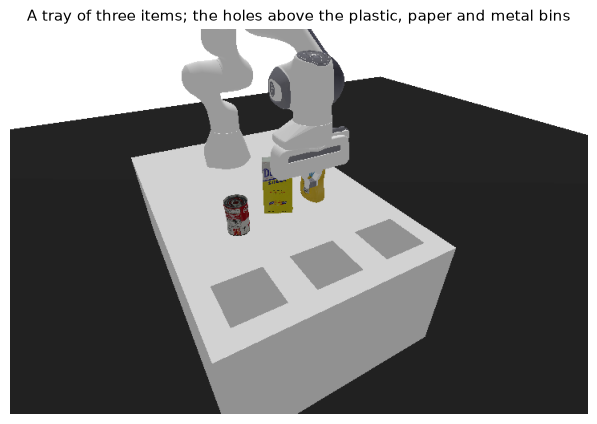

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import waste_env as W

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
env = W.make_env()
obs, info = env.reset(seed=0)
print("observation:", env.observation_space.shape, "| action:", env.action_space)
env.close()

picture = W.make_env(visual=True, n_distractors=2)          # display meshes only for pictures
picture.reset(seed=3)
plt.figure(figsize=(7.5, 5))
plt.imshow(picture.render())
plt.axis("off")
plt.title("A tray of three items; the holes above the plastic, paper and metal bins", fontsize=11)
plt.show()
picture.close()

## 3. Environment checks
**Scripted controller.** A hand-written controller (align the fingers with the item's narrow side, grasp, lift, carry,
let go) shows that every item can be sorted, and where the physics makes it hard. 20 episodes per item and condition.

In [7]:
conditions = {"nominal": W.NOMINAL, "training randomisation": W.TRAIN_RANDOMISATION, **W.OUT_OF_RANGE}
table = {}
for label, rand in conditions.items():
    row = {}
    for index, (name, _, _) in enumerate(W.ITEMS):
        s = W.YawScripted()
        rows = W.run_episodes(lambda obs, env: s.act(env), range(100, 120), randomisation=rand, on_start=s.reset, force_item=index)
        row[name] = 100 * np.mean([r["success"] for r in rows])
    table[label] = row
scripted = pd.DataFrame(table).T.round(0)
scripted["mean"] = scripted.mean(axis=1).round(1)
print("Scripted controller success % (20 episodes per cell)")
scripted

Scripted controller success % (20 episodes per cell)


,006_mustard_bottle,065-a_cups,065-c_cups,004_sugar_box,009_gelatin_box,005_tomato_soup_can,010_potted_meat_can,mean
nominal,100.0,100.0,100.0,90.0,100.0,100.0,100.0,98.6
training randomisation,90.0,100.0,100.0,85.0,100.0,85.0,100.0,94.3
heavy (mass x2),100.0,100.0,100.0,85.0,100.0,100.0,100.0,97.9
slippery (friction x0.5),0.0,100.0,100.0,95.0,100.0,100.0,100.0,85.0
large (size x1.2),40.0,100.0,0.0,35.0,100.0,0.0,100.0,53.6
small (size x0.8),100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


**Reward-farming checks.** Behaviours that never sort the item must not earn more than sorting it, and a
lift-and-put-down loop must earn nothing per loop. 50 test episodes per behaviour.

In [8]:
class Prefix(W.YawScripted):
    """Scripted controller up to `until`, then a fixed behaviour."""
    def __init__(self, until, behaviour):
        self.until, self.behaviour = until, behaviour
    def reset(self):
        super().reset(); self.t, self.loops = 0, 0
    def act(self, env):
        if self.phase < self.until:
            return super().act(env)
        self.t += 1
        return self.behaviour(self, env)

hold = lambda self, env: np.array([0, 0, 0, 0, -1.0], dtype=np.float32)
grasp_release = lambda self, env: np.array([0, 0, 0, 0, -1.0 if self.t % 9 < 5 else 1.0], dtype=np.float32)

def push(self, env):
    core = env.unwrapped
    ee = np.asarray(core.robot.get_ee_position())
    lo, hi = core.task.item_aabb()
    centre, goal = (lo + hi) / 2, np.asarray(core.task.goal)
    direction = (goal[:2] - centre[:2]) / max(np.linalg.norm(goal[:2] - centre[:2]), 1e-6)
    behind = np.array([*(centre[:2] - (0.5 * float(np.hypot(*(hi - lo)[:2])) + 0.03) * direction), lo[2] + 0.02])
    stage = getattr(self, "push_stage", 0)
    if stage == 0:
        target = behind + [0, 0, 0.12]
        self.push_stage = 1 if np.linalg.norm(ee - target) < 0.02 else 0
    elif stage == 1:
        target = behind
        self.push_stage = 2 if np.linalg.norm(ee - target) < 0.02 else 1
    else:
        target = np.array([*(goal[:2] + 0.05 * direction), lo[2] + 0.02])
    return np.array([*np.clip((target - ee) / 0.05, -1, 1), 0, -1.0], dtype=np.float32)

class LiftPutDownLoop(W.YawScripted):
    """Grasp and lift (scripted), put the item back on the table, let go, repeat; optionally then push it."""
    def __init__(self, then_push=False):
        self.then_push = then_push
    def reset(self):
        super().reset(); self.mode, self.t, self.loops = "scripted", 0, 0
    def act(self, env):
        lo, hi = env.unwrapped.task.item_aabb()
        if self.mode == "scripted":
            if self.phase == 5:
                self.mode = "down"
            else:
                return super().act(env)
        if self.mode == "down":
            if lo[2] < 0.006:
                self.mode, self.t = "open", 0
            return np.array([0, 0, -0.6, 0, -1.0], dtype=np.float32)
        if self.mode == "open":
            self.t += 1
            if self.t >= 5:
                self.loops += 1
                self.mode = "push" if self.then_push else "scripted"
                super().reset()
            return np.array([0, 0, 0.3, 0, 1.0], dtype=np.float32)
        return push(self, env)

class PushOnly:
    def reset(self): self.push_stage = 0
    def act(self, env): return push(self, env)

class Random:
    def reset(self): pass
    def act(self, env): return env.action_space.sample()

policies = [("scripted pick-and-place", W.YawScripted()), ("random policy", Random()),
            ("grasp and hold, no lift", Prefix(4, hold)), ("grasp-release loop, no lift", Prefix(4, grasp_release)),
            ("lift, put down, repeat", LiftPutDownLoop()), ("lift, put down, then push into hole", LiftPutDownLoop(True)),
            ("push into hole, no lift", PushOnly()), ("carry, then hold above hole", Prefix(6, hold))]
farming = {}
for label, policy in policies:
    env = W.make_env()
    out = []
    for seed in range(100, 150):
        obs, info = env.reset(seed=seed)
        env.action_space.seed(seed)
        policy.reset(); policy.push_stage = 0
        done, total, loop_totals, loops_seen = False, 0.0, [], 0
        while not done:
            obs, r, te, tr, info = env.step(policy.act(env))
            done, total = te or tr, total + r
            if getattr(policy, "loops", 0) > loops_seen:
                loops_seen = policy.loops
                loop_totals.append(total)
        out.append({"success": info["is_success"], "reward": total,
                    "per_loop": np.mean(np.diff(loop_totals)) if len(loop_totals) > 1 else np.nan})
    env.close()
    d = pd.DataFrame(out)
    farming[label] = {"success %": 100 * d.success.mean(), "mean reward": d.reward.mean(), "max reward": d.reward.max(),
                      "net reward per loop": d.per_loop.mean()}
pd.DataFrame(farming).T.round(2)

,success %,mean reward,max reward,net reward per loop
scripted pick-and-place,100.0,11.97,13.09,NaN
random policy,0.0,-2.42,0.46,NaN
"grasp and hold, no lift",0.0,1.16,2.04,NaN
"grasp-release loop, no lift",0.0,1.06,1.98,NaN
"lift, put down, repeat",0.0,0.66,5.86,-0.46
"lift, put down, then push into hole",0.0,-2.61,0.65,NaN
"push into hole, no lift",0.0,-2.59,0.86,NaN
"carry, then hold above hole",0.0,9.04,9.91,NaN


## 4. Algorithms and protocol
**Fairness principle.** The *problem* is identical for every algorithm; *inside* each algorithm, its standard
implementation is used, with the same tuning opportunity for all:

| Identical for all three | Algorithm-specific (each algorithm's standard form) |
|---|---|
| Environment, reward, observation, curriculum, randomisation | PPO: clipped policy updates on fresh rollouts (4 environments × rollout length), GAE |
| 1,000,000 environment steps per run | SAC: stochastic policy, twin critics, automatic entropy tuning, replay buffer of 1,000,000 |
| Hidden layers 256 × 256 (actor and critic) | TD3: deterministic policy with Gaussian exploration noise, twin critics, delayed updates, target smoothing, replay buffer of 1,000,000 |
| Three candidate configurations, the same automatic selection rule | |
| No observation or reward normalisation (supplementary comparison A adds it to PPO) | |
| CPU, one torch thread, the final model, deterministic test actions, the same seeds | |

**Selection stage.** Each of the three candidates per algorithm is trained with seeds 21, 22, 23. The configuration
with the highest mean success on 50 *selection* episodes (seeds 1000–1049, never used for testing) is chosen; ties are
broken by the lift rate, then the mean reward. **Final runs.** The selected configuration is trained with seeds 31–35
and evaluated on test seeds 3000–3049 (never seen before). **Supplementary comparisons** (reported separately):
A, PPO with observation and reward normalisation (a common PPO implementation practice; same procedure);
B, equal training time: SAC's training time for 1M steps given to TD3 (1.39M steps) and PPO (4M steps).

In [9]:
%%writefile train_eval.py
"""One final-stage run: train one Part C candidate configuration with one seed, then run the full evaluation.

    python train_eval.py --config TD3_default_like --seed 21 --stage selection     # selection stage: seeds 21, 22, 23
    python train_eval.py --config TD3_default_like --seed 31 --stage final         # final runs: seeds 31-35
    python train_eval.py --config PPO_small_lr --seed 21 --stage selection --normalize   # supplementary: PPO + VecNormalize
    python train_eval.py --config PPO_small_lr --seed 31 --stage final --equal-time      # supplementary: SAC's training time
    python train_eval.py --config TD3_default_like --seed 21 --stage selection --smoke   # 3,000-step code check only
    python train_eval.py --evaluate-only results/final/TD3_default_like_seed31     # evaluate a saved model again

Fixed for every algorithm (the team's fairness rules): the environment in waste_env.py with all final options,
256x256 hidden layers (PPO: separate actor and critic), 1,000,000 environment steps, one reverse curriculum shared by
all of a run's training environments, no observation or reward normalisation, CPU and one torch thread, the final
model (no checkpoint picking), deterministic actions in evaluation. Only the nine Part C candidates can be run; SAC and
TD3 keep their whole history in the replay buffer (1,000,000 transitions, the library default and the original papers').

Supplementary comparison (--normalize, PPO only): the same procedure with observation and reward normalisation
(VecNormalize), a common PPO implementation practice. Its runs go to results_ppo_norm/ and are reported separately; the
statistics saved during training are used, frozen, in every evaluation.

Evaluation (normal start; test seeds 100-149 in the selection stage, 3000-3049 in the final runs): one item with the
nominal properties, with the training randomisation and with each out-of-range condition; selection episodes (seeds
1000-1049, used only by select_config.py); trays of 3 and 4 items cleared outermost-first, normal and dense (items
0-1 cm apart), 20 trays each; test success of the checkpoints saved every 25k steps; diagnostics.
Results: results/<stage>/<config>_seed<seed>/ (summary.json, test_nominal.csv, model_final.zip, checkpoints/).
"""
import argparse
import json
import os
import platform
import random
import sys
import time
from importlib import metadata
from pathlib import Path

os.environ.setdefault("MPLBACKEND", "Agg")
import numpy as np
import pandas as pd
import torch
from stable_baselines3 import PPO, SAC, TD3
from stable_baselines3.common.callbacks import BaseCallback, CallbackList, CheckpointCallback
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.noise import NormalActionNoise
from stable_baselines3.common.utils import set_random_seed
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

HERE = Path(__file__).resolve().parent
sys.path.insert(0, str(HERE))
import waste_env as V  # noqa: E402

PROTOCOL = "3H-final-v2"
STEPS = 1_000_000
# supplementary: SAC's training time for 1,000,000 steps (M5, final runs: SAC/PPO time per step 3.96, SAC/TD3 1.39)
STEPS_EQUAL_TIME = {"PPO": 4_000_000, "TD3": 1_390_000}
STAGES = {"selection": {"seeds": (21, 22, 23), "test_start": 100}, "final": {"seeds": (31, 32, 33, 34, 35), "test_start": 3000}}
SELECTION_SEEDS = range(1000, 1050)
CONFIGS = {   # the Part C candidates (three per algorithm); replay buffer = whole history (library default)
    "PPO_default_like": dict(learning_rate=3e-4, n_steps=512, batch_size=64, n_epochs=10, gamma=0.99, gae_lambda=0.95, clip_range=0.2, ent_coef=0.0),
    "PPO_small_lr": dict(learning_rate=1e-4, n_steps=512, batch_size=128, n_epochs=10, gamma=0.98, gae_lambda=0.95, clip_range=0.2, ent_coef=0.0),
    "PPO_more_exploration": dict(learning_rate=3e-4, n_steps=256, batch_size=64, n_epochs=10, gamma=0.98, gae_lambda=0.95, clip_range=0.2, ent_coef=0.005),
    "SAC_default_like": dict(learning_rate=3e-4, buffer_size=1_000_000, learning_starts=1_000, batch_size=256, gamma=0.99, tau=0.005, train_freq=1, gradient_steps=1, ent_coef="auto", target_entropy="auto"),
    "SAC_robotics_gamma": dict(learning_rate=3e-4, buffer_size=1_000_000, learning_starts=2_000, batch_size=256, gamma=0.95, tau=0.02, train_freq=1, gradient_steps=1, ent_coef="auto", target_entropy="auto"),
    "SAC_more_exploration": dict(learning_rate=3e-4, buffer_size=1_000_000, learning_starts=2_000, batch_size=256, gamma=0.98, tau=0.01, train_freq=1, gradient_steps=1, ent_coef="auto", target_entropy=-2.0),
    "TD3_default_like": dict(learning_rate=1e-3, buffer_size=1_000_000, learning_starts=1_000, batch_size=256, gamma=0.99, tau=0.005, train_freq=1, gradient_steps=1, noise_sigma=0.10),
    "TD3_robotics_gamma": dict(learning_rate=3e-4, buffer_size=1_000_000, learning_starts=2_000, batch_size=256, gamma=0.95, tau=0.02, train_freq=1, gradient_steps=1, noise_sigma=0.10),
    "TD3_more_exploration": dict(learning_rate=3e-4, buffer_size=1_000_000, learning_starts=2_000, batch_size=256, gamma=0.98, tau=0.01, train_freq=1, gradient_steps=1, noise_sigma=0.20),
}
N_ENVS = {"PPO": 4, "SAC": 1, "TD3": 1}
ENV_FLAGS = dict(grasp_reward=True, regrasp=True, approach_stages=False, relative_obs=True, visual=False)
ALGOS = {"PPO": PPO, "SAC": SAC, "TD3": TD3}


def results_root(smoke, normalize=False, equal_time=False):
    return HERE / (("results_smoke" if smoke else "results") + ("_ppo_norm" if normalize else "") + ("_equal_time" if equal_time else ""))


def run_dir(config, seed, stage, smoke=False, normalize=False, equal_time=False):
    return results_root(smoke, normalize, equal_time) / stage / f"{config}_seed{seed}"


def machine():
    packages = ["pybullet", "panda-gym", "stable-baselines3", "gymnasium", "torch", "numpy"]
    return {"platform": platform.platform(), "processor": platform.machine(), "python": platform.python_version(),
            **{p: metadata.version(p) for p in packages}}


def make_model(config, seed, steps, out, normalize=False):
    """The model exactly as every run trains it: training environments with one shared curriculum, 256x256 network,
    the Part C configuration. Training-environment logs go to `out`. normalize=True (PPO only) wraps the training
    environments in VecNormalize (observations and rewards, VecNormalize defaults, gamma of the configuration)."""
    algo = config.split("_")[0]
    n_envs = N_ENVS[algo]

    def make_train_env(rank):
        def _init():
            env = V.make_env(randomisation=V.TRAIN_RANDOMISATION, curriculum_steps=int(V.CURRICULUM_FRACTION * steps / n_envs), **ENV_FLAGS)
            env = Monitor(env, filename=str(out / f"train_env_{rank}"), info_keywords=("start_type", "is_success"))
            env.reset(seed=seed + 10_000 * rank)              # no environment seed is shared between runs
            env.action_space.seed(seed + 10_000 * rank)
            return env
        return _init

    venv = DummyVecEnv([make_train_env(rank) for rank in range(n_envs)])
    shared_curriculum = V.CurriculumState()                   # one curriculum per policy, whatever the number of envs
    for e in venv.envs:
        e.unwrapped.curriculum = shared_curriculum
    if normalize:
        venv = VecNormalize(venv, norm_obs=True, norm_reward=True, gamma=CONFIGS[config]["gamma"])
    kwargs = dict(CONFIGS[config])
    kwargs["policy_kwargs"] = {"net_arch": dict(pi=[256, 256], vf=[256, 256]) if algo == "PPO" else [256, 256]}
    if algo == "TD3":
        sigma, n = kwargs.pop("noise_sigma"), venv.action_space.shape[-1]
        kwargs["action_noise"] = NormalActionNoise(np.zeros(n), sigma * np.ones(n))
    model = ALGOS[algo]("MlpPolicy", venv, seed=seed, device="cpu", verbose=0, **kwargs)
    return model, venv, shared_curriculum


class SaveObsNorm(BaseCallback):
    """Saves the VecNormalize observation statistics next to each checkpoint (same step number), as plain arrays."""

    def __init__(self, save_freq, path):
        super().__init__()
        self.save_freq, self.path = save_freq, path

    def _on_step(self):
        if self.n_calls % self.save_freq == 0:
            save_obs_norm(self.training_env, self.path / f"obs_norm_{self.num_timesteps}_steps.npz")
        return True


def save_obs_norm(venv, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(path, mean=venv.obs_rms.mean, var=venv.obs_rms.var, clip_obs=venv.clip_obs, epsilon=venv.epsilon)


def load_obs_norm(path):
    d = np.load(path)
    return {k: d[k] for k in ("mean", "var", "clip_obs", "epsilon")}


def train(config, seed, stage, smoke, normalize=False, equal_time=False):
    algo = config.split("_")[0]
    steps = 3_000 if smoke else (STEPS_EQUAL_TIME[algo] if equal_time else STEPS)
    n_envs = N_ENVS[algo]
    out = run_dir(config, seed, stage, smoke, normalize, equal_time)
    out.mkdir(parents=True, exist_ok=True)
    torch.set_num_threads(1)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); set_random_seed(seed)
    model, venv, shared_curriculum = make_model(config, seed, steps, out, normalize)
    every = 1_000 if smoke else 25_000
    save_freq = max(every // n_envs, 1)
    callbacks = [CheckpointCallback(save_freq=save_freq, save_path=str(out / "checkpoints"), name_prefix="model")]
    if normalize:
        callbacks.append(SaveObsNorm(save_freq, out / "checkpoints"))
    t0 = time.perf_counter()
    model.learn(total_timesteps=steps, callback=CallbackList(callbacks))
    minutes = (time.perf_counter() - t0) / 60
    model.save(str(out / "model_final"))
    if normalize:
        save_obs_norm(venv, out / "obs_norm_final.npz")
        model.obs_norm = load_obs_norm(out / "obs_norm_final.npz")
    venv.close()
    print(f"trained {config} seed {seed} ({stage}): {model.num_timesteps:,} steps in {minutes:.1f} min", flush=True)
    summary = {"protocol": PROTOCOL, "smoke test (not a result)": smoke, "config": config, "algorithm": algo,
               "observation and reward normalisation": normalize, "equal-time budget": equal_time,
               "settings": CONFIGS[config],
               "stage": stage, "seed": seed, "steps": int(model.num_timesteps), "training minutes": minutes,
               "test seeds": [STAGES[stage]["test_start"], STAGES[stage]["test_start"] + 49], "machine": machine(),
               "curriculum stages passed": shared_curriculum.log}
    return model, out, summary


def load_model(algo, path):
    """Loads only the network weights and plain settings of a saved model. The pickled parts (spaces, schedules, buffer
    classes) are replaced, so a model saved on another computer with other numpy/Python versions loads the same way,
    and nothing in a received file is unpickled."""
    env = V.make_env(**ENV_FLAGS)
    replace = {"policy_class": ALGOS[algo].policy_aliases["MlpPolicy"], "observation_space": env.observation_space,
               "action_space": env.action_space, "lr_schedule": lambda _: 0.0, "clip_range": 0.2, "train_freq": 1,
               "_last_obs": None, "_last_episode_starts": None, "_last_original_obs": None, "ep_info_buffer": None,
               "ep_success_buffer": None, "rollout_buffer_class": None, "replay_buffer_class": None}
    env.close()
    return ALGOS[algo].load(str(path), device="cpu", custom_objects=replace)


def policy(m):
    """Deterministic actions. A model trained with VecNormalize sees its observations normalised with the statistics
    saved at the end of training (or with its checkpoint), frozen, exactly as VecNormalize.normalize_obs does."""
    norm = getattr(m, "obs_norm", None)
    if norm is None:
        return lambda obs, env: m.predict(obs, deterministic=True)[0]
    scale = np.sqrt(norm["var"] + norm["epsilon"])
    return lambda obs, env: m.predict(np.clip((obs - norm["mean"]) / scale, -norm["clip_obs"], norm["clip_obs"]).astype(np.float32),
                                      deterministic=True)[0]


def summarise(rows):
    df = pd.DataFrame(rows)
    ok = df[df.success]
    return {"success %": 100 * df.success.mean(), "reached %": 100 * df.reached.mean(), "lifted %": 100 * df.lifted.mean(),
            "failure %": 100 * df.failure.mean(), "failed grasp %": 100 * df.failed_grasp.mean(),
            "mean reward": df.reward.mean(), "mean length": df.length.mean(), "regrasps/ep": df.regrasps.mean(),
            "success by item %": {k: 100 * float(g.success.mean()) for k, g in df.groupby("item")},
            "outcomes": df.outcome.value_counts().to_dict(),
            "movement (successful episodes)": {"steps": ok.length.mean(), "path m": ok.path.mean(),
                                               "gripper switches": ok.gripper_switches.mean(), "max lift m": ok.max_lift.mean()}
            if len(ok) else None,
            "movement (all episodes)": {"path m": df.path.mean(), "gripper switches": df.gripper_switches.mean()}}


def trays(act, seeds, dense):
    out = {}
    for n_items in (3, 4):
        results = [V.clear_tray(act, n_items, seed, dense_tray=dense, **ENV_FLAGS) for seed in seeds]
        attempts = [r for t in results for r in t["per_item"]]
        out[f"{n_items} items"] = {"per-item success %": 100 * np.mean([r["outcome"] == "success" for r in attempts]),
                                   "whole-tray success %": 100 * np.mean([t["whole_tray"] for t in results]),
                                   "items sorted per tray": float(np.mean([t["sorted"] for t in results])),
                                   "items attempted per tray": float(np.mean([t["attempted"] for t in results])),
                                   "items placed per tray": float(np.mean([t["items"] for t in results]))}
    return out


def from_starts(m, seeds):
    """Test success from each curriculum start (diagnostic: which part of the task is learned)."""
    out = {}
    for start in V.REVERSE_ORDER + V.APPROACH_STAGES:
        rows = V.run_episodes(policy(m), seeds, randomisation=V.NOMINAL, options={"start_type": start}, **ENV_FLAGS)
        out[start] = 100 * np.mean([r["success"] for r in rows])
    return out


def first_close_errors(m, seeds):
    """Pose of the gripper the first time it closes next to the item, from the normal start."""
    env = V.make_env(**ENV_FLAGS)
    core, rows, act = env.unwrapped, [], policy(m)
    for seed in seeds:
        obs, info = env.reset(seed=seed)
        done, previous, first = False, 1.0, None
        while not done:
            a = act(obs, env)
            task, robot = core.task, core.robot
            lo, hi = task.item_aabb()
            ee = np.asarray(robot.get_ee_position())
            if first is None and a[-1] < 0 <= previous and V.aabb_distance(ee, lo, hi) < 0.03:
                position, yaw, _ = task.grasp_pose()
                first = {"round": abs(task.local_size[0] - task.local_size[1]) < 0.01,
                         "yaw error deg": float(np.degrees(abs(((robot.get_yaw() - yaw + np.pi / 2) % np.pi) - np.pi / 2))),
                         "xy offset cm": float(100 * np.linalg.norm(ee[:2] - position[:2])),
                         "height error cm": float(100 * (ee[2] - position[2]))}
            previous = a[-1]
            obs, r, te, tr, info = env.step(a)
            done = te or tr
        if first:
            rows.append(first)
    env.close()
    df = pd.DataFrame(rows)
    if df.empty:
        return {"episodes with a close next to the item": 0}
    return {"episodes with a close next to the item": len(df),
            "median yaw error deg (non-round items)": float(df[~df["round"]]["yaw error deg"].median()) if (~df["round"]).any() else None,
            "median xy offset cm": float(df["xy offset cm"].median()), "median height error cm": float(df["height error cm"].median())}


def evaluate(model, out, summary, smoke, csv_name="test_nominal.csv"):
    n = 3 if smoke else 50
    start = summary["test seeds"][0]
    test = list(range(start, start + n))
    act = policy(model)
    nominal_rows = V.run_episodes(act, test, randomisation=V.NOMINAL, **ENV_FLAGS)
    pd.DataFrame(nominal_rows).to_csv(out / csv_name, index=False)
    summary["test: nominal"] = summarise(nominal_rows)
    summary["selection: nominal (seeds 1000-1049)"] = summarise(V.run_episodes(act, list(SELECTION_SEEDS)[:n], randomisation=V.NOMINAL, **ENV_FLAGS))
    summary["test: training randomisation"] = summarise(V.run_episodes(act, test, randomisation=V.TRAIN_RANDOMISATION, **ENV_FLAGS))
    for label, rand in V.OUT_OF_RANGE.items():
        summary[f"test: {label}"] = summarise(V.run_episodes(act, test, randomisation=rand, **ENV_FLAGS))
    tray_seeds = test[:1 if smoke else 20]
    summary["tray clearing (20 trays, nominal)"] = trays(act, tray_seeds, dense=False)
    summary["dense tray clearing (20 trays, nominal)"] = trays(act, tray_seeds, dense=True)
    curve = []
    for path in sorted((out / "checkpoints").glob("model_*_steps.zip"), key=lambda p: int(p.stem.split("_")[1])):
        m = load_model(summary["algorithm"], path)
        if summary.get("observation and reward normalisation"):
            m.obs_norm = load_obs_norm(path.parent / f"obs_norm_{path.stem.split('_')[1]}_steps.npz")
        rows = V.run_episodes(policy(m), test, randomisation=V.NOMINAL, **ENV_FLAGS)
        curve.append({"steps": int(path.stem.split("_")[1]), "success %": 100 * np.mean([r["success"] for r in rows]),
                      "lifted %": 100 * np.mean([r["lifted"] for r in rows]), "reached %": 100 * np.mean([r["reached"] for r in rows])})
    summary["checkpoint test success (nominal)"] = curve
    summary["test success from curriculum starts (30 seeds)"] = from_starts(model, test[:min(30, n)])
    summary["first close next to the item (nominal test)"] = first_close_errors(model, test)
    return summary


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--config", choices=list(CONFIGS))
    parser.add_argument("--seed", type=int)
    parser.add_argument("--stage", choices=list(STAGES))
    parser.add_argument("--smoke", action="store_true", help="3,000 steps and a few episodes: checks that the code runs")
    parser.add_argument("--normalize", action="store_true", help="supplementary comparison: PPO with VecNormalize")
    parser.add_argument("--equal-time", action="store_true", help="supplementary comparison: SAC's training time (PPO 4M, TD3 1.39M steps)")
    parser.add_argument("--evaluate-only", metavar="RUN_DIR", help="evaluate model_final.zip of a finished run again")
    args = parser.parse_args()
    torch.set_num_threads(1)
    if args.evaluate_only:
        out = Path(args.evaluate_only)
        old = json.load(open(out / "summary.json"))
        model = load_model(old["algorithm"], out / "model_final.zip")
        if old.get("observation and reward normalisation"):
            model.obs_norm = load_obs_norm(out / "obs_norm_final.npz")
        keep = ["protocol", "smoke test (not a result)", "config", "algorithm", "observation and reward normalisation",
                "equal-time budget", "equal-time budget (4M steps)", "settings", "stage", "seed", "steps", "training minutes", "test seeds", "curriculum stages passed"]
        summary = {**{k: old.get(k) for k in keep}, "machine (training)": old["machine"], "machine": machine()}
        summary = evaluate(model, out, summary, old["smoke test (not a result)"], "test_nominal_reevaluated.csv")
        json.dump(summary, open(out / "summary_reevaluated.json", "w"), indent=2, default=float)
        print("saved", out / "summary_reevaluated.json")
        return
    if not (args.config and args.seed is not None and args.stage):
        parser.error("--config, --seed and --stage are required (or --evaluate-only RUN_DIR)")
    if args.seed not in STAGES[args.stage]["seeds"]:
        parser.error(f"the {args.stage} stage uses seeds {STAGES[args.stage]['seeds']}")
    if args.normalize and not args.config.startswith("PPO"):
        parser.error("--normalize is the supplementary PPO comparison; SAC and TD3 run without normalisation")
    if args.equal_time and (args.config.split("_")[0] not in STEPS_EQUAL_TIME or args.stage != "final" or args.normalize):
        parser.error("--equal-time is the supplementary comparison for PPO and TD3: final stage, no normalisation")
    model, out, summary = train(args.config, args.seed, args.stage, args.smoke, args.normalize, args.equal_time)
    summary = evaluate(model, out, summary, args.smoke)
    json.dump(summary, open(out / "summary.json", "w"), indent=2, default=float)
    short = {k: round(v["success %"], 1) for k, v in summary.items() if k.startswith("test:")}
    print(json.dumps({"run": f"{args.stage}/{out.name}", "test success %": short,
                      "trays": summary["tray clearing (20 trays, nominal)"]}, indent=1, default=float))


if __name__ == "__main__":
    main()


Overwriting train_eval.py


In [10]:
import tempfile
from pathlib import Path
import torch
import train_eval as T

torch.set_num_threads(1)
configs = pd.DataFrame(T.CONFIGS).T
configs.insert(0, "training environments", [T.N_ENVS[c.split("_")[0]] for c in configs.index])
print("The nine Part C candidate configurations")
tidy = lambda v: "" if pd.isna(v) else (f"{int(v):,}" if isinstance(v, float) and float(v).is_integer() and v >= 10 else str(v))
display(configs.apply(lambda col: col.map(tidy)))

rows = []
with tempfile.TemporaryDirectory() as tmp:
    for config in ("PPO_default_like", "SAC_default_like", "TD3_default_like"):
        model, venv, _ = T.make_model(config, 21, T.STEPS, Path(tmp))
        p = model.policy
        if config.startswith("PPO"):
            nets = {"actor": p.mlp_extractor.policy_net, "critic": p.mlp_extractor.value_net}
        elif config.startswith("SAC"):
            nets = {"actor": p.actor.latent_pi, "critic (each of 2)": p.critic.qf0}
        else:
            nets = {"actor": p.actor.mu, "critic (each of 2)": p.critic.qf0}
        for part, net in nets.items():
            layers = [m.out_features for m in net.modules() if isinstance(m, torch.nn.Linear)]
            has_output = config[:3] != "PPO" and (part.startswith("critic") or config[:3] == "TD3")   # last Linear = output layer
            rows.append({"algorithm": config[:3], "network": part, "hidden layers": layers[:-1] if has_output else layers})
        venv.close()
pd.DataFrame(rows)

The nine Part C candidate configurations


,training environments,learning_rate,n_steps,batch_size,n_epochs,gamma,gae_lambda,clip_range,ent_coef,buffer_size,learning_starts,tau,train_freq,gradient_steps,target_entropy,noise_sigma
PPO_default_like,4,0.0003,512,64,10,0.99,0.95,0.2,0.0,,,,,,,
PPO_small_lr,4,0.0001,512,128,10,0.98,0.95,0.2,0.0,,,,,,,
PPO_more_exploration,4,0.0003,256,64,10,0.98,0.95,0.2,0.005,,,,,,,
SAC_default_like,1,0.0003,,256,,0.99,,,auto,1000000,1000,0.005,1,1,auto,
SAC_robotics_gamma,1,0.0003,,256,,0.95,,,auto,1000000,2000,0.02,1,1,auto,
SAC_more_exploration,1,0.0003,,256,,0.98,,,auto,1000000,2000,0.01,1,1,-2.0,
TD3_default_like,1,0.001,,256,,0.99,,,,"1,000,000","1,000",0.005,1.0,1.0,,0.1
TD3_robotics_gamma,1,0.0003,,256,,0.95,,,,"1,000,000","2,000",0.02,1.0,1.0,,0.1
TD3_more_exploration,1,0.0003,,256,,0.98,,,,"1,000,000","2,000",0.01,1.0,1.0,,0.2


,algorithm,network,hidden layers
0,PPO,actor,"[256, 256]"
1,PPO,critic,"[256, 256]"
2,SAC,actor,"[256, 256]"
3,SAC,critic (each of 2),"[256, 256]"
4,TD3,actor,"[256, 256]"
5,TD3,critic (each of 2),"[256, 256]"


## 5. Runner scripts
`run_all.py` runs the selection stage of every group, the automatic selection (`select_config.py`) and the final runs,
several runs at a time with a memory guard. `run_stage.py` runs one stage of one algorithm (used for supplementary
comparison B). `report_results.py` prints the mean and standard deviation over the final seeds.

In [11]:
%%writefile run_all.py
"""Runs the whole final experiment on one machine: the selection stage of every group, the configuration choice, then
the final runs, several runs at a time, without running out of memory.

    python run_all.py                       # main comparison (PPO, SAC, TD3) + supplementary PPO with VecNormalize
    python run_all.py --smoke               # 3,000-step check of the whole pipeline

Groups: SAC, TD3, PPO (main comparison) and PPO + normalisation (supplementary, results_ppo_norm/). Runs with a
summary.json are skipped, so the command can be started again after an interruption. A run starts only while fewer
than --max-parallel are running and at least --min-free-gb is available (the first run needs --stop-gb + 1 GB). Below
--stop-gb the newest running run is paused, then the next newest, and so on; paused runs resume one at a time, oldest
first, once --stop-gb + 1 GB is available. Log: results/run_all.log (a line per event).
"""
import argparse
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import psutil

HERE = Path(__file__).resolve().parent
sys.path.insert(0, str(HERE))
from train_eval import CONFIGS, STAGES, results_root, run_dir  # noqa: E402

GROUPS = [("SAC", False), ("TD3", False), ("PPO", False), ("PPO", True)]     # slowest first
parser = argparse.ArgumentParser()
parser.add_argument("--max-parallel", type=int, default=max(1, min(6, (os.cpu_count() or 2) - 1)))
TOTAL_GB = psutil.virtual_memory().total / 2**30
parser.add_argument("--min-free-gb", type=float, default=min(4.0, 0.25 * TOTAL_GB))
parser.add_argument("--stop-gb", type=float, default=min(2.0, 0.125 * TOTAL_GB))
parser.add_argument("--gap", type=float, default=60.0, help="seconds between two starts (5 with --smoke)")
parser.add_argument("--smoke", action="store_true")
args = parser.parse_args()
if args.smoke and "--gap" not in sys.argv:
    args.gap = 5.0
python = sys.executable
free = lambda: psutil.virtual_memory().available / 2**30
results_root(args.smoke).mkdir(parents=True, exist_ok=True)
LOG = open(results_root(args.smoke) / "run_all.log", "a")


def log(msg):
    line = f"{time.strftime('%m-%d %H:%M:%S')} {msg}"
    print(line, flush=True)
    LOG.write(line + "\n")
    LOG.flush()


def label(algo, norm):
    return algo + (" + norm" if norm else "")


def jobs_for(stage):
    jobs = []
    for algo, norm in GROUPS:
        if stage == "selection":
            configs = [c for c in CONFIGS if c.startswith(algo)]
        else:
            configs = [json.load(open(results_root(args.smoke, norm) / "selection" / f"selected_{algo}.json"))["selected"]]
        for config in configs:
            for seed in STAGES[stage]["seeds"]:
                if not (run_dir(config, seed, stage, args.smoke, norm) / "summary.json").exists():
                    jobs.append((config, seed, stage, norm))
    return jobs


def run(jobs):
    running, paused, last_start, last_wait = [], [], 0.0, 0.0       # running: (proc, name), oldest first
    while jobs or running:
        for proc, name in list(running):
            if proc.poll() is not None:
                running.remove((proc, name))
                if proc.pid in paused:
                    paused.remove(proc.pid)
                log(f"done: {name} (exit {proc.returncode}{', see its log' if proc.returncode else ''}) | free {free():.1f} GB")
        active = [(p, n) for p, n in running if p.pid not in paused]
        if free() < args.stop_gb and len(active) > 1:                   # pause the newest active run (keep one going)
            proc, name = active[-1]
            psutil.Process(proc.pid).suspend()
            paused.append(proc.pid)
            log(f"paused {name}: free {free():.1f} GB")
        elif paused and free() > args.stop_gb + 1.0:                    # resume the oldest paused run
            pid = min(paused, key=lambda p: [q.pid for q, _ in running].index(p))
            psutil.Process(pid).resume()
            paused.remove(pid)
            log(f"resumed pid {pid}: free {free():.1f} GB")
        room = free() >= args.min_free_gb or (not running and free() >= args.stop_gb + 1.0)
        if jobs and not paused and len(running) < args.max_parallel and room and time.time() - last_start >= args.gap:
            config, seed, stage, norm = jobs.pop(0)
            name = f"{stage}/{config}{'+norm' if norm else ''}_seed{seed}"
            logs = results_root(args.smoke, norm) / stage / "logs"
            logs.mkdir(parents=True, exist_ok=True)
            cmd = [python, str(HERE / "train_eval.py"), "--config", config, "--seed", str(seed), "--stage", stage]
            cmd += (["--smoke"] if args.smoke else []) + (["--normalize"] if norm else [])
            proc = subprocess.Popen(cmd, stdout=open(logs / f"{config}_seed{seed}.log", "w"), stderr=subprocess.STDOUT, cwd=HERE)
            running.append((proc, name))
            last_start = time.time()
            log(f"started: {name} | running {len(running)} | free {free():.1f} GB")
        elif jobs and not running and time.time() - last_wait >= 300:
            last_wait = time.time()
            log(f"waiting for memory: free {free():.1f} GB, the first run starts at {args.stop_gb + 1.0:.1f} GB")
        time.sleep(5)


t0 = time.time()
selection = jobs_for("selection")
log(f"selection stage: {len(selection)} runs to do")
run(selection)
for algo, norm in GROUPS:
    cmd = [python, str(HERE / "select_config.py"), "--algo", algo] + (["--smoke"] if args.smoke else []) + (["--normalize"] if norm else [])
    out = subprocess.run(cmd, capture_output=True, text=True, cwd=HERE)
    chosen = [l for l in out.stdout.splitlines() if l.startswith("selected")]
    log(f"{label(algo, norm)}: {chosen[0] if chosen else 'SELECTION FAILED: ' + (out.stdout + out.stderr)[-500:]}")
    if not chosen:
        sys.exit(1)
final = jobs_for("final")
log(f"final runs: {len(final)} runs to do")
run(final)
log(f"all finished in {(time.time() - t0) / 3600:.1f} h")


Overwriting run_all.py


In [12]:
%%writefile run_stage.py
"""Runs every run of one stage for one algorithm, several at a time, without running out of memory.

    python run_stage.py --algo TD3 --stage selection      # 3 Part C candidates x seeds 21-23 = 9 runs
    python select_config.py --algo TD3                    # picks the configuration (writes selected_TD3.json)
    python run_stage.py --algo TD3 --stage final          # the selected configuration x seeds 31-35 = 5 runs
    python run_stage.py --algo PPO --stage selection --normalize   # supplementary PPO comparison (results_ppo_norm/)

Runs that already have a summary.json are skipped, so the command can simply be started again after an interruption
(an unfinished run starts again from the beginning). A run starts only while fewer than --max-parallel are running and
at least --min-free-gb of memory is available (default: 4 GB, or a quarter of the memory on smaller machines; the
first run needs only --stop-gb + 1 GB);
below --stop-gb the newest run is paused until --stop-gb + 1 GB is available again.
Logs: results/<stage>/logs/.
"""
import argparse
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import psutil

HERE = Path(__file__).resolve().parent
sys.path.insert(0, str(HERE))
from train_eval import CONFIGS, STAGES, results_root, run_dir  # noqa: E402

parser = argparse.ArgumentParser()
parser.add_argument("--algo", choices=["PPO", "SAC", "TD3"], required=True)
parser.add_argument("--stage", choices=list(STAGES), required=True)
parser.add_argument("--max-parallel", type=int, default=max(1, min(6, (os.cpu_count() or 2) - 1)))
TOTAL_GB = psutil.virtual_memory().total / 2**30                    # one run needs about 0.2-0.8 GB
parser.add_argument("--min-free-gb", type=float, default=min(4.0, 0.25 * TOTAL_GB))
parser.add_argument("--stop-gb", type=float, default=min(2.0, 0.125 * TOTAL_GB))
parser.add_argument("--gap", type=float, default=60.0, help="seconds between two starts (5 with --smoke)")
parser.add_argument("--smoke", action="store_true", help="3,000-step code check of the whole pipeline")
parser.add_argument("--normalize", action="store_true", help="supplementary comparison: PPO with VecNormalize")
parser.add_argument("--equal-time", action="store_true", help="supplementary comparison: SAC's training time (final stage)")
args = parser.parse_args()
if args.smoke and "--gap" not in sys.argv:
    args.gap = 5.0
if args.normalize and args.algo != "PPO":
    parser.error("--normalize is the supplementary PPO comparison")
ROOT = results_root(args.smoke, args.normalize, args.equal_time)

if args.stage == "selection":
    configs = [c for c in CONFIGS if c.startswith(args.algo)]
else:
    chosen = ROOT / "selection" / f"selected_{args.algo}.json"
    if not chosen.exists():
        sys.exit(f"{chosen} not found: run the selection stage and select_config.py --algo {args.algo} first")
    configs = [json.load(open(chosen))["selected"]]
jobs = [(c, s) for c in configs for s in STAGES[args.stage]["seeds"]
        if not (run_dir(c, s, args.stage, args.smoke, args.normalize, args.equal_time) / "summary.json").exists()]
logs = ROOT / args.stage / "logs"
logs.mkdir(parents=True, exist_ok=True)
free = lambda: psutil.virtual_memory().available / 2**30
log = lambda msg: print(time.strftime("%H:%M:%S"), msg, flush=True)
log(f"{args.algo} {args.stage}: {len(jobs)} runs to do ({', '.join(f'{c} seed {s}' for c, s in jobs) or 'none'})")
running, paused, last_start, t0, last_wait = [], [], 0.0, time.time(), 0.0

while jobs or running:
    for proc, name in list(running):
        if proc.poll() is not None:
            running.remove((proc, name))
            log(f"done: {name} (exit {proc.returncode}{', see log' if proc.returncode else ''}) | free {free():.1f} GB")
    if free() < args.stop_gb and running:                              # memory emergency: pause the newest run
        proc, name = running[-1]
        if proc.pid not in paused:
            psutil.Process(proc.pid).suspend()                      # works on macOS, Linux and Windows
            paused.append(proc.pid)
            log(f"paused {name}: free {free():.1f} GB")
    elif paused and free() > args.stop_gb + 1.0:                      # a paused run keeps its memory, so resuming needs little
        pid = paused.pop()
        psutil.Process(pid).resume()
        log(f"resumed pid {pid}: free {free():.1f} GB")
    # one run needs well under 1 GB, so the first run may start below --min-free-gb (but 1 GB above --stop-gb)
    room = free() >= args.min_free_gb or (not running and free() >= args.stop_gb + 1.0)
    if jobs and not paused and len(running) < args.max_parallel and room and time.time() - last_start >= args.gap:
        config, seed = jobs.pop(0)
        name = f"{config}_seed{seed}"
        cmd = [sys.executable, str(HERE / "train_eval.py"), "--config", config, "--seed", str(seed), "--stage", args.stage]
        out = open(logs / f"{name}.log", "w")
        flags = (["--smoke"] if args.smoke else []) + (["--normalize"] if args.normalize else []) + (["--equal-time"] if args.equal_time else [])
        proc = subprocess.Popen(cmd + flags, stdout=out, stderr=subprocess.STDOUT, cwd=HERE)
        running.append((proc, name))
        last_start = time.time()
        log(f"started: {name} | running {len(running)} | free {free():.1f} GB")
    elif jobs and not running and time.time() - last_wait >= 300:   # nothing can start: say why instead of waiting silently
        last_wait = time.time()
        log(f"waiting for memory: free {free():.1f} GB, the first run starts at {args.stop_gb + 1.0:.1f} GB (close other apps)")
    time.sleep(5)
log(f"finished in {(time.time() - t0) / 60:.0f} min")


Overwriting run_stage.py


In [13]:
%%writefile select_config.py
"""Selection stage: picks one configuration per algorithm with the rule fixed in Part C.

    python select_config.py --algo TD3

Ranks the three Part C candidates of the algorithm by their mean over the selection-stage training seeds of the selection episodes
(seeds 1000-1049, never used as test episodes): highest success rate, then highest lift rate, then highest mean episode
reward. Only complete runs made with this package's protocol count. Writes results/selection/selected_<ALGO>.json
(--normalize: the supplementary PPO comparison in results_ppo_norm/).
"""
import argparse
import json
import sys
from pathlib import Path

import pandas as pd

HERE = Path(__file__).resolve().parent
sys.path.insert(0, str(HERE))
from train_eval import CONFIGS, PROTOCOL, STAGES, STEPS, results_root, run_dir  # noqa: E402

KEY = "selection: nominal (seeds 1000-1049)"
parser = argparse.ArgumentParser()
parser.add_argument("--algo", choices=["PPO", "SAC", "TD3"], required=True)
parser.add_argument("--smoke", action="store_true")
parser.add_argument("--normalize", action="store_true")
args = parser.parse_args()
pd.set_option("display.width", 200)

rows, problems = [], []
candidates = [c for c in CONFIGS if c.startswith(args.algo)]
for config in candidates:
    for seed in STAGES["selection"]["seeds"]:
        path = run_dir(config, seed, "selection", args.smoke, args.normalize) / "summary.json"
        if not path.exists():
            problems.append(f"missing: {config} seed {seed}")
            continue
        s = json.load(open(path))
        if (s["protocol"] != PROTOCOL or s["smoke test (not a result)"] != args.smoke or (not args.smoke and s["steps"] < STEPS)
                or bool(s.get("observation and reward normalisation")) != args.normalize):
            problems.append(f"not a valid run of this protocol: {path}")
            continue
        r = s[KEY]
        rows.append({"config": config, "seed": seed, "success %": r["success %"], "lifted %": r["lifted %"],
                     "mean reward": r["mean reward"]})
if problems:
    sys.exit("selection not possible yet:\n  " + "\n  ".join(problems))

df = pd.DataFrame(rows)
print(df.round(2).to_string(index=False))
mean = df.groupby("config")[["success %", "lifted %", "mean reward"]].mean()
ranked = sorted(candidates, key=lambda c: tuple(mean.loc[c]), reverse=True)
seeds = "-".join(str(x) for x in (STAGES["selection"]["seeds"][0], STAGES["selection"]["seeds"][-1]))
print(f"\nmean over seeds {seeds} (ranked):")
print(mean.loc[ranked].round(2).to_string())
out = results_root(args.smoke, args.normalize) / "selection" / f"selected_{args.algo}.json"
json.dump({"selected": ranked[0], "rule": f"mean over training seeds {seeds} of selection-episode success, then lift, then reward",
           "means": mean.loc[ranked].to_dict(orient="index")}, open(out, "w"), indent=2)
print(f"\nselected {args.algo} configuration: {ranked[0]}  (saved {out.relative_to(HERE)})")


Overwriting select_config.py


In [14]:
%%writefile report_results.py
"""Final results of every algorithm found in results/final/ (copy teammates' run folders there to compare).

    python report_results.py

Prints, per algorithm, the mean and standard deviation over the final seeds of each test, and saves
results/final/final_results.csv. Uses summary_reevaluated.json when a run was evaluated again on one machine.
--normalize reports the supplementary PPO comparison (results_ppo_norm/).
"""
import argparse
import json
import sys
from pathlib import Path

import pandas as pd

HERE = Path(__file__).resolve().parent
sys.path.insert(0, str(HERE))
from train_eval import PROTOCOL, results_root  # noqa: E402

parser = argparse.ArgumentParser()
parser.add_argument("--smoke", action="store_true")
parser.add_argument("--normalize", action="store_true")
parser.add_argument("--equal-time", action="store_true")
args = parser.parse_args()
pd.set_option("display.width", 220)

rows = []
ROOT = results_root(args.smoke, args.normalize, args.equal_time)
for folder in sorted((ROOT / "final").glob("*_seed*")):
    files = [folder / "summary_reevaluated.json", folder / "summary.json"]
    path = next((f for f in files if f.exists()), None)
    if path is None:
        continue
    s = json.load(open(path))
    if s["protocol"] != PROTOCOL:
        print("skipped (other protocol):", folder.name)
        continue
    row = {"algorithm": s["algorithm"] + (" + norm" if s.get("observation and reward normalisation") else "")
                        + (f" {s['steps'] / 1e6:.2f}M steps" if s.get("equal-time budget") or s.get("equal-time budget (4M steps)") else ""),
           "config": s["config"], "seed": s["seed"], "evaluated": path.stem,
           "nominal reached %": s["test: nominal"]["reached %"], "nominal lifted %": s["test: nominal"]["lifted %"]}
    for key, value in s.items():
        if key.startswith("test: "):
            row[key[6:] + " success %"] = value["success %"]
    for key in ("tray clearing (20 trays, nominal)", "dense tray clearing (20 trays, nominal)"):
        label = "dense tray" if key.startswith("dense") else "tray"
        for n, t in s[key].items():
            row[f"{label} {n}: per-item %"] = t["per-item success %"]
            row[f"{label} {n}: whole %"] = t["whole-tray success %"]
    ok = s["test: nominal"]["movement (successful episodes)"]
    row["steps per success"] = ok["steps"] if ok else float("nan")
    rows.append(row)
if not rows:
    sys.exit("no final runs found in " + str(ROOT / "final"))

df = pd.DataFrame(rows)
df.to_csv(ROOT / "final" / "final_results.csv", index=False)
print(df[["algorithm", "config", "seed", "evaluated", "nominal success %"]].to_string(index=False))
metrics = [c for c in df.columns if c not in ("algorithm", "config", "seed", "evaluated")]
table = df.groupby("algorithm")[metrics].agg(["mean", "std"])
print("\nmean (sd) over final seeds:")
for algo, r in table.iterrows():
    n = int((df.algorithm == algo).sum())
    print(f"\n{algo} ({df[df.algorithm == algo].config.iloc[0]}, {n} seeds)")
    for m in metrics:
        print(f"  {m:<40} {r[(m, 'mean')]:6.1f} ({r[(m, 'std')]:.1f})")


Overwriting report_results.py


## 6. How the experiment was run
On the M5 MacBook, from this folder (five runs at a time):

```
python run_all.py --max-parallel 5 --min-free-gb 3.0 --stop-gb 2.0          # main comparison + supplementary A
python run_stage.py --algo PPO --stage final --equal-time --max-parallel 5  # supplementary B (selected config)
python run_stage.py --algo TD3 --stage final --equal-time --max-parallel 5
```
The log lines and every run's record are read back here. (Re-running this part elsewhere, e.g. on Colab, needs the
result files: `results_bundle.zip`, shared with this notebook, unpacked next to it.)

In [15]:
import glob, json, re

from pathlib import Path
import zipfile
if not Path("results/run_all.log").exists():                 # e.g. on Colab: unpack the result files shared with this notebook
    if Path("results_bundle.zip").exists():
        zipfile.ZipFile("results_bundle.zip").extractall(".")
    else:
        raise FileNotFoundError("Result files not found: upload results_bundle.zip (shared with this notebook) next to it and run this cell again.")

def log_summary(path):
    lines = [l for l in open(path).read().splitlines() if not l.startswith("pybullet build")]
    done = [l for l in lines if " done: " in l]
    failed = [l for l in done if "(exit 0)" not in l]
    print(f"{path}: {len(done)} runs finished, {len(failed)} failed; first line: {lines[0][:60]} | last line: {lines[-1]}")

log_summary("results/run_all.log")
log_summary("results_equal_time/run_stage_PPO.log")
log_summary("results_equal_time/run_stage_TD3.log")

def load(root, stage, algo="*"):
    return [json.load(open(f)) for f in sorted(glob.glob(f"{root}/{stage}/{algo}_*_seed*/summary.json"))]

records = []
for root, label in (("results", ""), ("results_ppo_norm", " + normalisation"), ("results_equal_time", " (equal time)")):
    for stage in ("selection", "final"):
        for s in load(root, stage):
            records.append({"group": s["algorithm"] + label, "stage": stage, "config": s["config"], "seed": s["seed"],
                            "steps": s["steps"], "training min": s["training minutes"], "protocol": s["protocol"],
                            "machine": f"{s['machine']['processor']} {s['machine']['platform'][:12]}, torch {s['machine']['torch']}, numpy {s['machine']['numpy']}"})
records = pd.DataFrame(records)
print("runs per group and stage:")
display(records.groupby(["group", "stage"]).agg(runs=("seed", "size"), steps=("steps", "max"),
                                                training_min_mean=("training min", "mean")).round(1))
print("machine:", ", ".join(records.machine.unique()), "| protocol:", ", ".join(records.protocol.unique()))

results/run_all.log: 56 runs finished, 0 failed; first line: 10-24 13:44:33 selection stage: 36 runs to do | last line: 10-24 23:54:56 all finished in 10.2 h
results_equal_time/run_stage_PPO.log: 5 runs finished, 0 failed; first line: 00:06:20 PPO final: 5 runs to do (PPO_small_lr seed 31, PPO_ | last line: 02:13:35 finished in 127 min
results_equal_time/run_stage_TD3.log: 5 runs finished, 0 failed; first line: 02:15:10 TD3 final: 5 runs to do (TD3_robotics_gamma seed 31 | last line: 03:47:03 finished in 92 min
runs per group and stage:


runs    steps  training_min_mean
group               stage                                      
PPO                 final         5  1001472               21.5
                    selection     9  1001472               23.0
PPO (equal time)    final         5  4001792              103.2
PPO + normalisation final         5  1001472               20.9
                    selection     9  1001472               22.3
SAC                 final         5  1000000               85.0
                    selection     9  1000000               85.6
TD3                 final         5  1000000               61.3
                    selection     9  1000000               58.4
TD3 (equal time)    final         5  1390000               80.3

machine: arm64 macOS-26.6.2, torch 2.14.1, numpy 1.26.4 | protocol: 3H-final-v2


## 7. Results
### 7.1 Selection stage
Mean over training seeds 21–23 of the 50 selection episodes (seeds 1000–1049). The selected configuration is the first
of each group.

In [16]:
KEY = "selection: nominal (seeds 1000-1049)"
rows = []
for root, label in (("results", ""), ("results_ppo_norm", " + normalisation")):
    for s in load(root, "selection"):
        rows.append({"group": s["algorithm"] + label, "config": s["config"], "seed": s["seed"],
                     "success %": s[KEY]["success %"], "lifted %": s[KEY]["lifted %"], "mean reward": s[KEY]["mean reward"]})
selection = pd.DataFrame(rows)
means = selection.groupby(["group", "config"])[["success %", "lifted %", "mean reward"]].mean()
means["per seed success %"] = selection.groupby(["group", "config"])["success %"].apply(lambda x: " / ".join(f"{v:.0f}" for v in x))
means = means.reset_index().sort_values(["group", "success %", "lifted %", "mean reward"], ascending=[True, False, False, False])
chosen = {}
for root, label in (("results", ""), ("results_ppo_norm", " + normalisation")):
    for f in glob.glob(f"{root}/selection/selected_*.json"):
        chosen[f.split("_")[-1][:-5] + label] = json.load(open(f))["selected"]
means["selected"] = [chosen.get(g) == c for g, c in zip(means.group, means.config)]
means.round(2)

,group,config,success %,lifted %,mean reward,per seed success %,selected
2,PPO,PPO_small_lr,0.00,0.00,0.19,0 / 0 / 0,True
0,PPO,PPO_default_like,0.00,0.00,-0.32,0 / 0 / 0,False
1,PPO,PPO_more_exploration,0.00,0.00,-1.43,0 / 0 / 0,False
5,PPO + normalisation,PPO_small_lr,0.00,0.00,0.22,0 / 0 / 0,True
3,PPO + normalisation,PPO_default_like,0.00,0.00,-0.94,0 / 0 / 0,False
4,PPO + normalisation,PPO_more_exploration,0.00,0.00,-1.45,0 / 0 / 0,False
8,SAC,SAC_robotics_gamma,95.33,99.33,13.77,96 / 98 / 92,True
7,SAC,SAC_more_exploration,42.67,50.00,5.87,86 / 0 / 42,False
6,SAC,SAC_default_like,0.00,6.00,-3.53,0 / 0 / 0,False
11,TD3,TD3_robotics_gamma,0.00,2.00,-0.11,0 / 0 / 0,True


### 7.2 Main comparison
Final runs: the selected configuration, training seeds 31–35, 50 test episodes per condition (seeds 3000–3049); trays:
20 trays per size. Mean (standard deviation) over the five seeds.

In [17]:
TESTS = ["test: nominal", "test: training randomisation", "test: heavy (mass x2)", "test: slippery (friction x0.5)",
         "test: large (size x1.2)", "test: small (size x0.8)"]

def final_row(s):
    n = s["test: nominal"]
    row = {"group": s["algorithm"], "config": s["config"], "seed": s["seed"],
           "reached %": n["reached %"], "lifted %": n["lifted %"]}
    for t in TESTS:
        row[t[6:] + " success %"] = s[t]["success %"]
    for key, label in (("tray clearing (20 trays, nominal)", "tray"), ("dense tray clearing (20 trays, nominal)", "dense tray")):
        for n_items, t in s[key].items():
            row[f"{label} {n_items[0]}: per-item %"] = t["per-item success %"]
            row[f"{label} {n_items[0]}: whole tray %"] = t["whole-tray success %"]
    return row

final = pd.DataFrame([final_row(s) for s in load("results", "final")])
metrics = [c for c in final.columns if c not in ("group", "config", "seed")]
summary = final.groupby("group")[metrics].agg(["mean", "std"])
table = pd.DataFrame({g: {m: f"{summary.loc[g, (m, 'mean')]:.1f} ({summary.loc[g, (m, 'std')]:.1f})" for m in metrics}
                      for g in ("PPO", "SAC", "TD3")})
table.loc["configuration"] = [final[final.group == g].config.iloc[0] for g in table.columns]
display(table.loc[["configuration"] + metrics])
print("Test success per seed (nominal):")
final.pivot_table(index="group", columns="seed", values="nominal success %")

,PPO,SAC,TD3
configuration,PPO_small_lr,SAC_robotics_gamma,TD3_robotics_gamma
reached %,63.6 (18.5),95.2 (10.7),22.4 (7.8)
lifted %,0.0 (0.0),92.4 (15.9),1.2 (2.7)
nominal success %,0.0 (0.0),89.2 (19.8),0.0 (0.0)
training randomisation success %,0.0 (0.0),88.8 (19.7),0.0 (0.0)
heavy (mass x2) success %,0.0 (0.0),86.0 (23.7),0.4 (0.9)
slippery (friction x0.5) success %,0.0 (0.0),79.6 (23.4),0.0 (0.0)
large (size x1.2) success %,0.0 (0.0),57.2 (16.8),0.0 (0.0)
small (size x0.8) success %,0.0 (0.0),89.6 (20.0),0.0 (0.0)
tray 3: per-item %,0.0 (0.0),83.6 (19.3),0.3 (0.8)


Test success per seed (nominal):


seed,31,32,33,34,35
group,,,,,
PPO,0.0,0.0,0.0,0.0,0.0
SAC,100.0,100.0,98.0,54.0,94.0
TD3,0.0,0.0,0.0,0.0,0.0


### 7.3 Learning curves
Test success and reach from the normal start for the checkpoints saved every 25,000 steps (50 test episodes each);
line = mean of the five final runs, band = lowest to highest run.

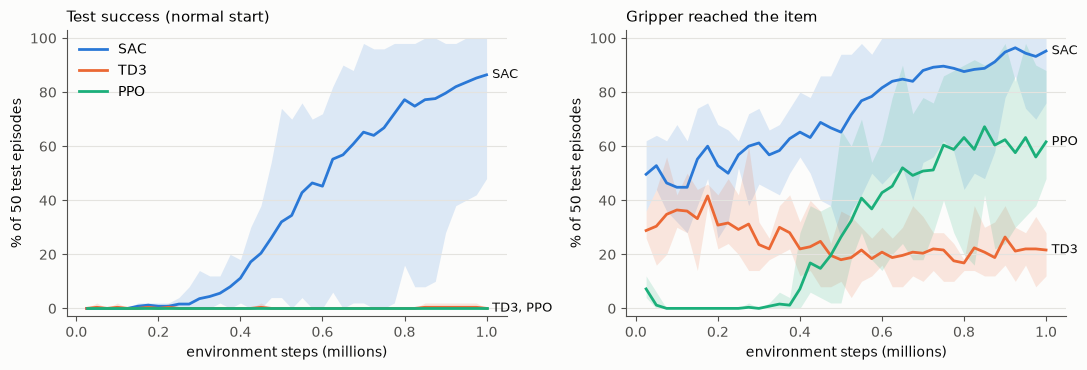

In [18]:
COLORS = {"SAC": "#2a78d6", "TD3": "#eb6834", "PPO": "#1baf7a"}          # one colour per algorithm, in every figure
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid.axis": "y", "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 11, "legend.frameon": False, "lines.linewidth": 2})

def curves(runs, field):
    frames = [pd.DataFrame(s["checkpoint test success (nominal)"]).set_index("steps")[field] for s in runs]
    d = pd.concat(frames, axis=1)
    return d.index / 1e6, d.mean(axis=1), d.min(axis=1), d.max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, field, title in zip(axes, ("success %", "reached %"), ("Test success (normal start)", "Gripper reached the item")):
    for algo in ("SAC", "TD3", "PPO"):
        x, mean, lo, hi = curves(load("results", "final", algo), field)
        ax.fill_between(x, lo, hi, color=COLORS[algo], alpha=0.15, linewidth=0)
        ax.plot(x, mean, color=COLORS[algo], label=algo)
        if field == "reached %" or algo == "SAC":                     # TD3 and PPO overlap at 0 on the left
            ax.annotate(algo, (x[-1], mean.iloc[-1]), xytext=(4, 0), textcoords="offset points", color=INK, va="center", fontsize=9)
    if field == "success %":
        ax.annotate("TD3, PPO", (1.0, 0), xytext=(4, 0), textcoords="offset points", color=INK, va="center", fontsize=9)
    ax.set_title(title, loc="left")
    ax.set_xlabel("environment steps (millions)")
    ax.set_ylabel("% of 50 test episodes")
    ax.set_ylim(-3, 103)
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

### 7.4 Where each algorithm stops
Test success of the final models from each training start (30 episodes per start and run), from the easiest (item held
above the correct hole) to the normal start; and the training success per start type over the whole run (with
exploration). `above item` (gripper open and aligned 7 cm above the grasp point) is not a training start: it isolates the
descent onto the item.

start,above_bin,in_hand,pre_grasp,above_item,normal
algorithm,,,,,
PPO,12.7,4.7,3.3,0.0,0.0
SAC,98.7,97.3,95.3,84.7,89.2
TD3,40.0,28.0,22.7,0.0,0.0


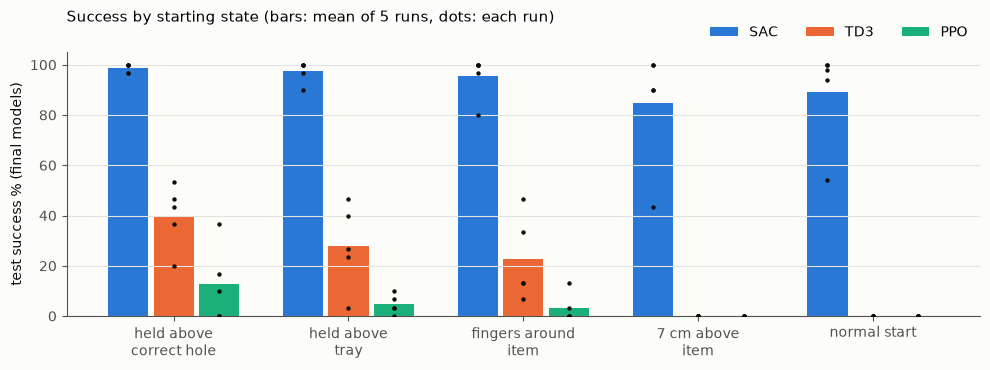

Training success % per start type (with exploration, whole run, mean of 5 runs):


start,above_bin,in_hand,pre_grasp,normal
algorithm,,,,
PPO,46.0,2.7,never reached,0.0
SAC,71.0,49.4,65.3,53.4
TD3,38.5,16.2,28.9,0.2


In [19]:
START_ORDER = ["above_bin", "in_hand", "pre_grasp", "above_item", "normal"]
LABELS = {"above_bin": "held above\ncorrect hole", "in_hand": "held above\ntray", "pre_grasp": "fingers around\nitem",
          "above_item": "7 cm above\nitem", "normal": "normal start"}
rows = []
for s in load("results", "final"):
    starts = dict(s["test success from curriculum starts (30 seeds)"], normal=s["test: nominal"]["success %"])
    for start in START_ORDER:
        rows.append({"algorithm": s["algorithm"], "seed": s["seed"], "start": start, "success %": starts[start]})
stages = pd.DataFrame(rows)
display(stages.pivot_table(index="algorithm", columns="start", values="success %")[START_ORDER].round(1))

fig, ax = plt.subplots(figsize=(10, 3.8))
width = 0.26
for k, algo in enumerate(("SAC", "TD3", "PPO")):
    d = stages[stages.algorithm == algo]
    m = d.groupby("start")["success %"].mean().reindex(START_ORDER)
    x = np.arange(len(START_ORDER)) + (k - 1) * width
    ax.bar(x, m.values, width - 0.03, color=COLORS[algo], label=algo)
    for i, start in enumerate(START_ORDER):
        ax.scatter(np.full(5, x[i]), d[d.start == start]["success %"], s=10, color=INK, zorder=3, linewidths=0)
ax.set_xticks(np.arange(len(START_ORDER)), [LABELS[s] for s in START_ORDER])
ax.set_ylabel("test success % (final models)")
ax.set_ylim(0, 105)
ax.set_title("Success by starting state (bars: mean of 5 runs, dots: each run)", loc="left", pad=22)
ax.legend(ncol=3, loc="lower right", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

train_rows = []
for s in load("results", "final"):
    folder = f"results/final/{s['config']}_seed{s['seed']}"
    monitor = pd.concat([pd.read_csv(f, skiprows=1) for f in glob.glob(folder + "/train_env_*.monitor.csv")])
    for start, g in monitor.groupby("start_type"):
        train_rows.append({"algorithm": s["algorithm"], "seed": s["seed"], "start": start, "success %": 100 * g.is_success.mean()})
print("Training success % per start type (with exploration, whole run, mean of 5 runs):")
pd.DataFrame(train_rows).pivot_table(index="algorithm", columns="start", values="success %").reindex(columns=["above_bin", "in_hand", "pre_grasp", "normal"]).round(1).fillna("never reached")

### 7.5 Skills over training
The checkpoints at 0.2M, 0.4M, 0.6M (end of the curriculum), 0.8M and 1M steps, tested from four starts (20 test
episodes per start and run). Computed once from the saved checkpoints and stored in `results/analysis/`.

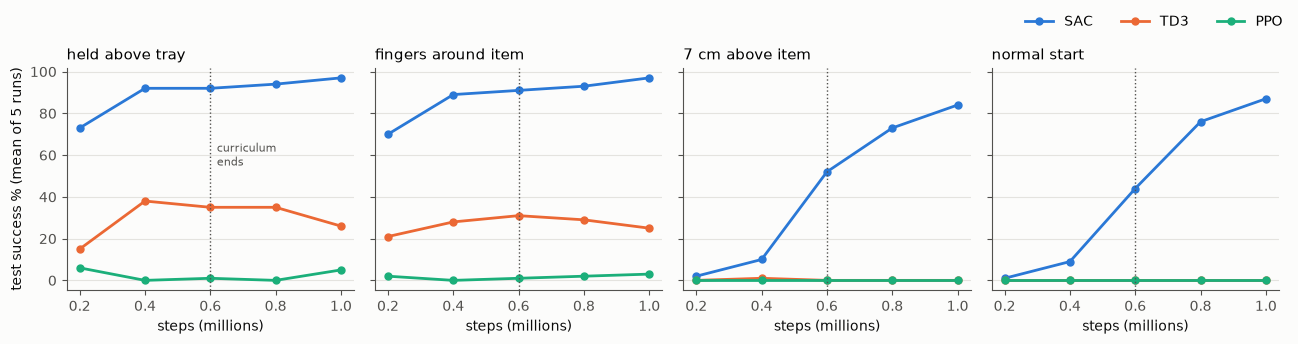

steps                 200000   400000   600000   800000   1000000
algorithm start                                                  
PPO       above_item      0.0      0.0      0.0      0.0      0.0
          in_hand         6.0      0.0      1.0      0.0      5.0
          normal          0.0      0.0      0.0      0.0      0.0
          pre_grasp       2.0      0.0      1.0      2.0      3.0
SAC       above_item      2.0     10.0     52.0     73.0     84.0
          in_hand        73.0     92.0     92.0     94.0     97.0
          normal          1.0      9.0     44.0     76.0     87.0
          pre_grasp      70.0     89.0     91.0     93.0     97.0
TD3       above_item      0.0      1.0      0.0      0.0      0.0
          in_hand        15.0     38.0     35.0     35.0     26.0
          normal          0.0      0.0      0.0      0.0      0.0
          pre_grasp      21.0     28.0     31.0     29.0     25.0

In [20]:
cache = Path("results/analysis/stage_checkpoints.csv")
if not cache.exists():
    cache.parent.mkdir(parents=True, exist_ok=True)
    rows = []
    for s in load("results", "final"):
        folder = Path(f"results/final/{s['config']}_seed{s['seed']}")
        for step in (200_000, 400_000, 600_000, 800_000, 1_000_000):
            model = T.load_model(s["algorithm"], folder / "checkpoints" / f"model_{step}_steps.zip")
            for start in ("in_hand", "pre_grasp", "above_item", "normal"):
                r = W.run_episodes(T.policy(model), range(3000, 3020), options=None if start == "normal" else {"start_type": start}, **T.ENV_FLAGS)
                rows.append({"algorithm": s["algorithm"], "seed": s["seed"], "steps": step, "start": start,
                             "success %": 100 * np.mean([x["success"] for x in r]), "lifted %": 100 * np.mean([x["lifted"] for x in r])})
    pd.DataFrame(rows).to_csv(cache, index=False)
skills = pd.read_csv(cache)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, start in zip(axes, ("in_hand", "pre_grasp", "above_item", "normal")):
    for algo in ("SAC", "TD3", "PPO"):
        m = skills[(skills.algorithm == algo) & (skills.start == start)].groupby("steps")["success %"].mean()
        ax.plot(m.index / 1e6, m.values, color=COLORS[algo], marker="o", markersize=5, label=algo)
    ax.axvline(0.6, color=MUTED, linewidth=1, linestyle=":")
    ax.set_title(LABELS[start].replace("\n", " "), loc="left")
    ax.set_xlabel("steps (millions)")
axes[0].set_ylabel("test success % (mean of 5 runs)")
axes[0].text(0.62, 55, "curriculum\nends", color=MUTED, fontsize=8)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper right", bbox_to_anchor=(1.0, 1.02))
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()
skills.pivot_table(index=["algorithm", "start"], columns="steps", values="success %").round(0)

### 7.6 Robustness and multi-item trays (SAC)
TD3 and PPO are at or near 0% in every condition (table in 7.2). Bars: mean of SAC's five runs; dots: each run.

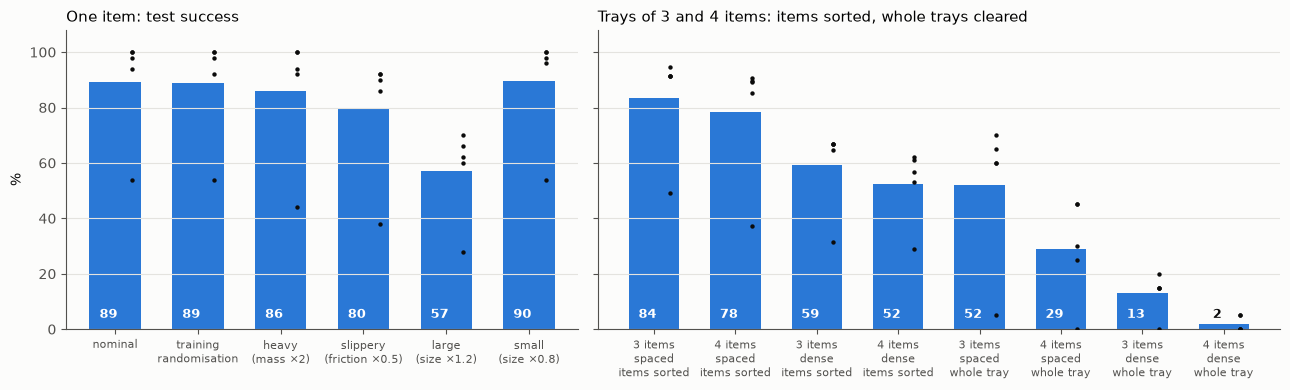

,nominal success %,training randomisation success %,heavy (mass x2) success %,slippery (friction x0.5) success %,large (size x1.2) success %,small (size x0.8) success %,tray 3: per-item %,tray 4: per-item %,dense tray 3: per-item %,dense tray 4: per-item %,tray 3: whole tray %,tray 4: whole tray %,dense tray 3: whole tray %,dense tray 4: whole tray %
seed,,,,,,,,,,,,,,
31,100.0,100.0,100.0,90.0,70.0,100.0,95.0,90.0,67.0,62.0,60.0,25.0,15.0,5.0
32,100.0,100.0,100.0,92.0,66.0,98.0,91.0,91.0,65.0,53.0,65.0,45.0,20.0,0.0
33,98.0,98.0,92.0,92.0,62.0,100.0,92.0,89.0,67.0,57.0,70.0,45.0,15.0,0.0
34,54.0,54.0,44.0,38.0,28.0,54.0,49.0,37.0,31.0,29.0,5.0,0.0,0.0,0.0
35,94.0,92.0,94.0,86.0,60.0,96.0,91.0,85.0,67.0,61.0,60.0,30.0,15.0,5.0


In [21]:
sac = final[final.group == "SAC"]
single = ["nominal success %", "training randomisation success %", "heavy (mass x2) success %", "slippery (friction x0.5) success %",
          "large (size x1.2) success %", "small (size x0.8) success %"]
trays = ["tray 3: per-item %", "tray 4: per-item %", "dense tray 3: per-item %", "dense tray 4: per-item %",
         "tray 3: whole tray %", "tray 4: whole tray %", "dense tray 3: whole tray %", "dense tray 4: whole tray %"]
short = {"nominal success %": "nominal", "training randomisation success %": "training\nrandomisation",
         "heavy (mass x2) success %": "heavy\n(mass ×2)", "slippery (friction x0.5) success %": "slippery\n(friction ×0.5)",
         "large (size x1.2) success %": "large\n(size ×1.2)", "small (size x0.8) success %": "small\n(size ×0.8)"}
for c in trays:
    layout, rest = c.split(": ")
    short[c] = f"{layout[-1]} items\n{'dense' if layout.startswith('dense') else 'spaced'}\n{'items sorted' if 'per-item' in rest else 'whole tray'}"
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, gridspec_kw={"width_ratios": [6, 8]})
for ax, cols, title in ((axes[0], single, "One item: test success"), (axes[1], trays, "Trays of 3 and 4 items: items sorted, whole trays cleared")):
    x = np.arange(len(cols))
    ax.bar(x, sac[cols].mean().values, 0.62, color=COLORS["SAC"])
    for i, c in enumerate(cols):
        ax.scatter(np.full(len(sac), i + 0.2), sac[c], s=10, color=INK, zorder=3, linewidths=0)
        low = sac[c].mean() < 10                                   # too short for a label inside the bar
        ax.text(i - 0.08, sac[c].mean() + 1 if low else 3, f"{sac[c].mean():.0f}", ha="center", va="bottom", fontsize=9,
                color=INK if low else "white", fontweight="bold")
    ax.set_xticks(x, [short[c] for c in cols], fontsize=8)
    ax.set_title(title, loc="left")
axes[0].set_ylabel("%")
axes[0].set_ylim(0, 108)
plt.tight_layout()
plt.show()
sac[["seed"] + single + trays].set_index("seed").round(0)

### 7.7 How SAC moves
Successful test episodes of the final SAC runs (nominal items): length, gripper path, open/close switches, highest lift;
and the gripper pose the first time it closes next to the item.

In [22]:
rows = []
for s in load("results", "final", "SAC"):
    m = s["test: nominal"]["movement (successful episodes)"]
    c = s["first close next to the item (nominal test)"]
    rows.append({"seed": s["seed"], "steps": m["steps"], "gripper path m": m["path m"], "gripper switches": m["gripper switches"],
                 "max lift m": m["max lift m"], "wrist error at first close (deg)": c["median yaw error deg (non-round items)"],
                 "xy offset at first close (cm)": c["median xy offset cm"]})
moves = pd.DataFrame(rows).set_index("seed")
moves.loc["mean"] = moves.mean()
moves.round(2)

,steps,gripper path m,gripper switches,max lift m,wrist error at first close (deg),xy offset at first close (cm)
seed,,,,,,
31,20.16,0.91,2.80,0.12,7.59,0.51
32,19.86,0.87,2.52,0.10,4.28,0.54
33,20.06,0.90,2.31,0.12,6.02,0.82
34,24.85,0.96,3.48,0.14,5.36,1.45
35,22.91,0.93,2.66,0.12,2.63,0.72
mean,21.57,0.91,2.75,0.12,5.18,0.81


### 7.8 Supplementary comparison A: PPO with observation and reward normalisation
PPO implementations commonly normalise observations and rewards (Andrychowicz et al., 2021). Same candidates, seeds,
selection rule, budget and evaluation as the main comparison, with Stable-Baselines3 `VecNormalize` (statistics frozen in
evaluation). SAC and TD3 are not normalised, as in their original papers.

In [23]:
rows = []
for root, label in (("results", "PPO"), ("results_ppo_norm", "PPO + normalisation")):
    for s in load(root, "final", "PPO"):
        n, starts = s["test: nominal"], s["test success from curriculum starts (30 seeds)"]
        rows.append({"group": label, "config": s["config"], "seed": s["seed"], "success %": n["success %"],
                     "reached %": n["reached %"], "lifted %": n["lifted %"],
                     "closes next to item (of 50)": s["first close next to the item (nominal test)"]["episodes with a close next to the item"],
                     "from above hole %": starts["above_bin"], "from held %": starts["in_hand"], "from fingers around %": starts["pre_grasp"]})
ppo_cmp = pd.DataFrame(rows)
ppo_cmp.groupby(["group", "config"]).mean(numeric_only=True).drop(columns="seed").round(1)

,,success %,reached %,lifted %,closes next to item (of 50),from above hole %,from held %,from fingers around %
group,config,,,,,,,
PPO,PPO_small_lr,0.0,63.6,0.0,12.4,12.7,4.7,3.3
PPO + normalisation,PPO_small_lr,0.0,88.0,0.0,33.4,64.7,2.0,2.0


### 7.9 Supplementary comparison B: equal training time
PPO and TD3 are faster per step than SAC (training time per 1M steps, five runs at a time: PPO about 21 min, TD3 61 min,
SAC 85 min). Given SAC's training time instead of its number of steps, the selected configurations get 4,000,000 (PPO)
and 1,390,000 (TD3) steps; same seeds and evaluation. This comparison was added after the main results.

,steps,training min,success %,reached %,lifted %,from held %,from 7 cm above %
group,,,,,,,
SAC 1M,1000000.0,85.0,89.2,95.2,92.4,97.3,84.7
TD3 1M,1000000.0,61.3,0.0,22.4,1.2,28.0,0.0
TD3 1.39M,1390000.0,80.3,0.0,42.4,8.0,47.3,0.0
PPO 1M,1001472.0,21.5,0.0,63.6,0.0,4.7,0.0
PPO 4M,4001792.0,103.2,0.0,97.2,0.0,0.0,0.0


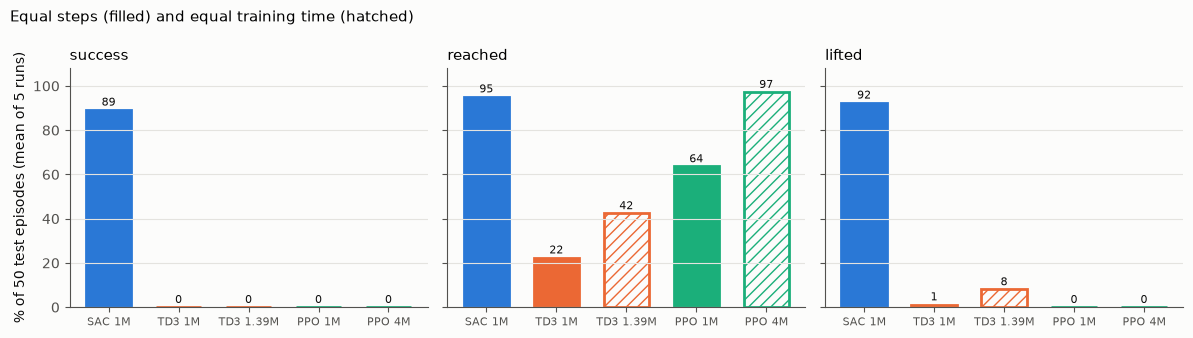

In [24]:
rows = []
for root, algo, label in (("results", "SAC", "SAC 1M"), ("results", "TD3", "TD3 1M"), ("results_equal_time", "TD3", "TD3 1.39M"),
                          ("results", "PPO", "PPO 1M"), ("results_equal_time", "PPO", "PPO 4M")):
    for s in load(root, "final", algo):
        n, starts = s["test: nominal"], s["test success from curriculum starts (30 seeds)"]
        rows.append({"group": label, "algorithm": algo, "steps": s["steps"], "training min": s["training minutes"],
                     "success %": n["success %"], "reached %": n["reached %"], "lifted %": n["lifted %"],
                     "from held %": starts["in_hand"], "from 7 cm above %": starts["above_item"]})
budget = pd.DataFrame(rows)
order = ["SAC 1M", "TD3 1M", "TD3 1.39M", "PPO 1M", "PPO 4M"]
display(budget.groupby("group").mean(numeric_only=True).reindex(order).round(1))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, field in zip(axes, ("success %", "reached %", "lifted %")):
    m = budget.groupby("group")[field].mean().reindex(order)
    for i, g in enumerate(order):
        algo = g.split()[0]
        extra = g in ("TD3 1.39M", "PPO 4M")
        ax.bar(i, m[g], 0.65, color=COLORS[algo] if not extra else "none", edgecolor=COLORS[algo], linewidth=2, hatch="///" if extra else None)
        ax.annotate(f"{m[g]:.0f}", (i, m[g]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK)
    ax.set_xticks(range(len(order)), order, fontsize=8)
    ax.set_title(field.replace(" %", ""), loc="left")
axes[0].set_ylabel("% of 50 test episodes (mean of 5 runs)")
axes[0].set_ylim(0, 108)
fig.suptitle("Equal steps (filled) and equal training time (hatched)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

### 7.10 A SAC rollout
One test episode of a final SAC run, rendered with the display meshes.

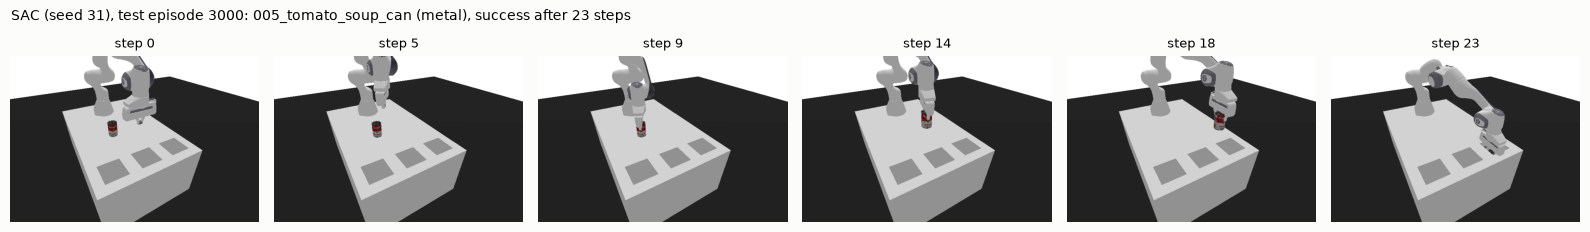

In [25]:
model = T.load_model("SAC", Path("results/final/SAC_robotics_gamma_seed31/model_final.zip"))
act = T.policy(model)
show = W.make_env(visual=True)
for seed in range(3000, 3050):
    obs, info = show.reset(seed=seed)
    frames, done = [show.render()], False
    while not done:
        obs, r, te, tr, info = show.step(act(obs, show))
        done = te or tr
        frames.append(show.render())
    if info["is_success"] and info["item"] in ("006_mustard_bottle", "004_sugar_box", "005_tomato_soup_can"):
        break
picks = np.linspace(0, len(frames) - 1, 6).round().astype(int)
fig, axes = plt.subplots(1, 6, figsize=(16, 2.4))
for ax, k in zip(axes, picks):
    ax.imshow(frames[k])
    ax.set_title(f"step {k}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"SAC (seed 31), test episode {seed}: {info['item']} ({info['category']}), {info['outcome']} after {len(frames) - 1} steps",
             x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.show()
show.close()

## 8. Summary and limitations
- **Same number of environment steps (1M):** only SAC learned the task (89.2% ± 19.8 test success; four of
  five runs 94–100%). It also cleared trays of three items (84% of items; 52% of trays completely) and
  dense trays less well (59% of items), mostly because grasping one item knocks over its neighbours.
- **PPO** reached the item in 64% of episodes but never lifted it; it did not even learn to carry an item it
  was already holding. With normalisation (supplementary A) it reached the item in 88% of episodes and tried
  to grasp more often, still without a lift. With SAC's training time (4M steps, supplementary B) reach rose to
  97% and success stayed 0%.
- **TD3** learned the later stages (it lifts an item when its fingers are already around it) but never the descent onto
  the item from above, so it did not succeed from the normal start; with SAC's training time (1.39M steps) it lifted
  in 8% of episodes, success still 0%.
- **Interpretation:** with a limited sample budget and a precise grasp, SAC's experience replay (against PPO) and its
  adaptive, entropy-driven exploration (against TD3's fixed Gaussian noise) made the difference. The conclusion is
  limited to these conditions.

**Limitations.** One environment and one machine; five final seeds and 50 test episodes per condition (about ±14
percentage points at 50%); three hand-designed candidate configurations per algorithm, of which only SAC and TD3 had
one based on published robot-arm settings (γ = 0.95); the environment's design options were tested during development
with SAC; no observation normalisation in the main comparison (supplementary A adds it to PPO); no hindsight experience
replay or demonstrations (HER cannot be used by PPO and would change the task to a goal-reaching one); supplementary
comparison B was planned after the main results; perfect object state (no perception noise); upright items only.